# plot the well comparison at different location

some wells are close to the river and some wells are far away from the river. The groundwater level and species concentration from observation wells are compared at different locations. 

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [1]:
import geopandas as gpd
from shapely.geometry import Point

In [2]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [5]:
# %matplotlib notebook
# import glob, datetime, ipdb, pickle, pyproj, json, mplleaflet, geopandas, fiona, sys, cartopy, \
#          math, folium, base64
import glob, pickle
import numpy as np
import h5py as h5
import math
import pyproj

import matplotlib 
# matplotlib.use('Agg')
import matplotlib.pyplot as plt
# plt.style.use('seaborn-notebook')
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates

import pandas as pd
# import modin.pandas as pd
import ipywidgets as ipyw
# import cartopy.crs as ccrs
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# import datetime
from datetime import timedelta, datetime
from scipy import interpolate
# from ipyleaflet import *
# from geojson import Feature, FeatureCollection, Point
from geopandas import GeoDataFrame
# from shapely.geometry import Point
from natsort import natsorted, ns, natsort_keygen
from sklearn.metrics import  mean_squared_error
# from folium.plugins import FloatImage
# from folium import IFrame

import re, lzma

# from tqdm import tqdm_notebook
from tqdm.notebook import tqdm

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

from myfunc import insertNA, printname, batch_delta_to_time, get_rmse
from modvis import utils

from fav_colors import fav_colors

from collections import Counter
import seaborn as sns

In [6]:
date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
model_origin = [551600, 104500] 

P_atm = 101325
rho = 997.16
g_const = 9.81

### import well data

In [7]:
data_dir = "/global/cfs/cdirs/m1800/pin/Reach_scale_model/data/"
#fname_300A_well_data = data_dir + 'well_data/SFA_all_wells.csv'    # not found
fname_300A_well_ID = data_dir + 'well_data/300A_well_coordinates_all_HRcontact.txt'    # different name
fname_HEIS_auto_well = data_dir + 'well_data/mvAwln.csv'
fname_HEIS_auto_wellID = data_dir + 'well_data/mvAwln_wellID_updated.csv'
fname_HEIS_manual_well = data_dir + 'well_data/HYDRAULIC_HEAD_MV.csv'
fname_HEIS_manual_wellID = data_dir + 'well_data/HYDRAULIC_HEAD_MV_WellID.csv'

In [8]:
wellID_300A = pd.read_csv(fname_300A_well_ID,sep='\t')
wellID_300A.columns=['WellName','Northing','Easting']
wellID_300A.set_index('WellName',inplace=True)
wellID_300A_sub = wellID_300A[['Easting','Northing']]

In [11]:
print(wellID_300A_sub.head())
print(len(wellID_300A_sub.index))

              Easting    Northing
WellName                         
399-1-10A  594346.570  116733.990
399-1-11   594109.840  116660.160
399-1-12   594040.260  116548.510
399-1-13A  593910.440  116557.250
399-1-15   593988.332  116964.243
85


In [12]:
HEIS_manual_wellID = pd.read_csv(fname_HEIS_manual_wellID, dtype={'EASTING':np.float64, 'NORTHING':np.float64})
HEIS_manual_wellID.rename(columns = {'WELL_ID':'Well_ID', 'WELL_NAME':'WellName', 'NORTHING':'Northing', 'EASTING':'Easting'}, \
                         inplace = True)
HEIS_manual_wellID.set_index('WellName', inplace=True)
HEIS_manual_wellID_sub = HEIS_manual_wellID[['Easting', 'Northing']]

In [13]:
print(HEIS_manual_wellID_sub.head())
print(len(HEIS_manual_wellID_sub.index))

              Easting   Northing
WellName                        
199-B2-12  565368.440  145363.68
199-B2-13  564086.520  145264.56
199-B3-1   565561.455  145342.08
199-B3-46  565899.570  145369.04
199-B3-47  565388.660  145368.95
2232


In [14]:
HEIS_auto_wellID = pd.read_csv(fname_HEIS_auto_wellID, na_values=['#REF!'], dtype={'Easting':np.float64, 'Northing':np.float64})
HEIS_auto_wellID.rename(columns = {'WellNumber':'Well_ID'}, inplace = True)
HEIS_auto_wellID.set_index('WellName', inplace=True)
HEIS_auto_wellID_sub = HEIS_auto_wellID[['Easting', 'Northing']]

In [15]:
print(HEIS_auto_wellID_sub.head())
print(len(HEIS_auto_wellID_sub.index))

              Easting    Northing
WellName                         
199-H3-2A  577624.608  152750.068
199-H3-3   577562.091  152363.166
199-H3-4   577544.287  152293.210
199-H3-5   577454.697  152287.496
699-39-79  565890.897  135411.873
312


In [42]:
well_coord = pd.concat([wellID_300A_sub, HEIS_auto_wellID_sub],axis=0).dropna()       # the HEIS_manual dataset is too old, discard
well_coord = well_coord[~well_coord.index.duplicated(keep='first')]
print(well_coord.head())
print(len(well_coord.index))

              Easting    Northing
WellName                         
399-1-10A  594346.570  116733.990
399-1-11   594109.840  116660.160
399-1-12   594040.260  116548.510
399-1-13A  593910.440  116557.250
399-1-15   593988.332  116964.243
386


### visualize the location of the wells

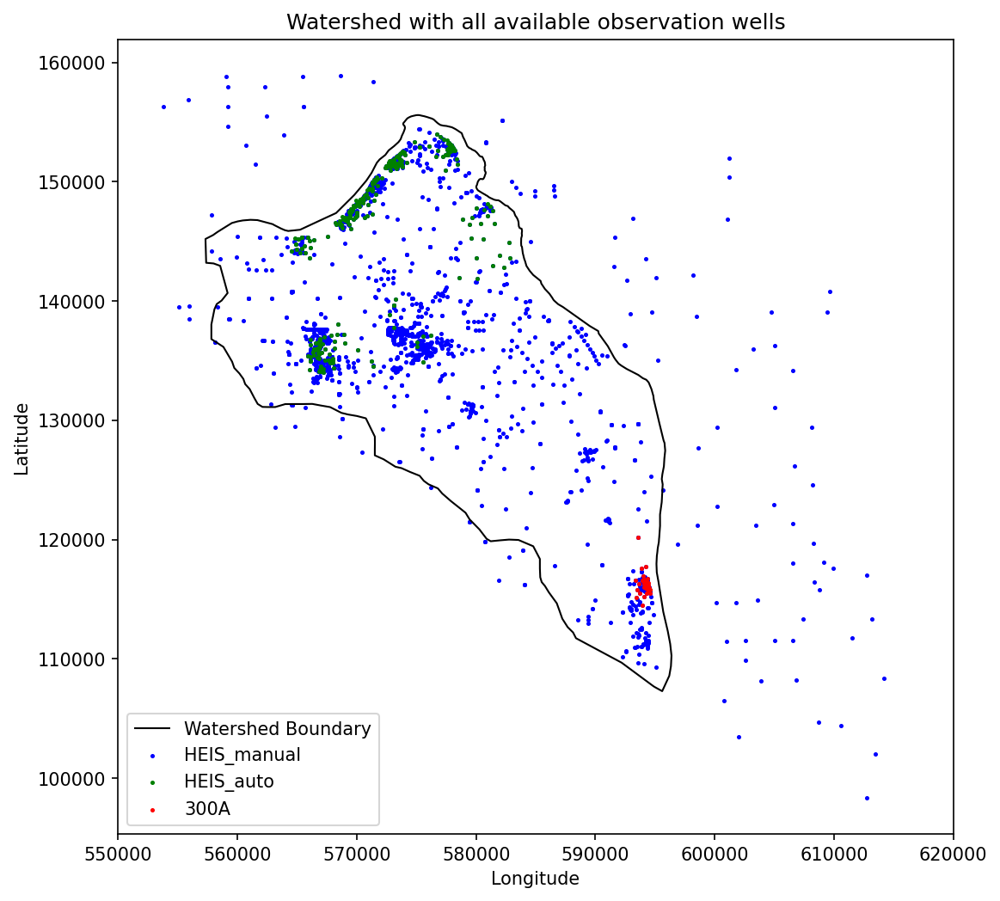

In [10]:
# plot the location of these well in the watershed map
watershed_shp = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp"
watershed_bound = gpd.read_file(watershed_shp)

coord_300A = list(zip(wellID_300A_sub['Easting'],wellID_300A_sub['Northing']))
geometry_300A = [Point(xy) for xy in coord_300A]
coord_300A_gdf = gpd.GeoDataFrame(geometry=geometry_300A, crs=watershed_bound.crs)

coord_HEIS_manual = list(zip(HEIS_manual_wellID_sub['Easting'],HEIS_manual_wellID_sub['Northing']))
geometry_HEIS_manual = [Point(xy) for xy in coord_HEIS_manual]
coord_HEIS_manual_gdf = gpd.GeoDataFrame(geometry=geometry_HEIS_manual, crs=watershed_bound.crs)

coord_HEIS_auto = list(zip(HEIS_auto_wellID_sub['Easting'],HEIS_auto_wellID_sub['Northing']))
geometry_HEIS_auto = [Point(xy) for xy in coord_HEIS_auto]
coord_HEIS_auto_gdf = gpd.GeoDataFrame(geometry=geometry_HEIS_auto, crs=watershed_bound.crs)

#plot
fig, ax = plt.subplots(figsize=(12,8))
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')
coord_HEIS_manual_gdf.plot(ax=ax, color='blue', markersize=2, label='HEIS_manual')
coord_HEIS_auto_gdf.plot(ax=ax, color='green', markersize=2, label='HEIS_auto')
coord_300A_gdf.plot(ax=ax, color='red', markersize=2, label='300A')

ax.set_title('Watershed with all available observation wells')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_xlim(550000, 620000)
plt.legend()

plt.show()

# import well obs data

### import well water level data

In [17]:
#fname_300A_Well_Data = data_dir + 'well_data/300A_Well_Data/399-1-1_3var.csv'
#WellData_300A = pd.read_csv(fname_300A_Well_Data)

In [16]:
fname_tec_files = data_dir + 'well_data/300A_Well_Data/*.csv'       # input all .csv file
tec_files = glob.glob(fname_tec_files)
tec_files = natsorted(tec_files)
assert(len(tec_files) > 0),"No such files found in the specified directory."

In [17]:
well_300A = pd.DataFrame()

for ifile in tqdm(tec_files[:]):
    filename = ifile.split('/')[-1]
    wellname = filename.split('_')[0]
    idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
    iheader = list(np.asarray(idf_header_row.values).flatten())
    idf = pd.read_table(ifile, sep=',',header=None, names=iheader, skiprows=1, engine='python') 
    idf['WellName'] = wellname
    well_300A = pd.concat([well_300A, idf], axis=0, join='outer')
    
print(well_300A.head)

  0%|          | 0/48 [00:00<?, ?it/s]

<bound method NDFrame.head of               Date/Time(PST)  Temperature(degC)  SpC(mS/cm)    WL(m) WellName
0       01-Jan-2008 00:00:00              18.37       0.363  105.191  399-1-1
1       01-Jan-2008 01:00:00              18.38       0.363  105.184  399-1-1
2       01-Jan-2008 02:00:00              18.39       0.362  105.176  399-1-1
3       01-Jan-2008 03:00:00              18.40       0.362  105.175  399-1-1
4       01-Jan-2008 04:00:00              18.39       0.362  105.180  399-1-1
...                      ...                ...         ...      ...      ...
152727                   NaN              18.34       0.128  106.018    SWS-1
152728                   NaN              18.30       0.128  106.025    SWS-1
152729                   NaN              18.23       0.128  106.030    SWS-1
152730                   NaN              18.19       0.129  106.037    SWS-1
152731                   NaN              18.20       0.128  106.048    SWS-1

[8236943 rows x 5 columns]>


In [18]:
print(well_300A.columns)

Index(['Date/Time(PST)', 'Temperature(degC)', 'SpC(mS/cm)', 'WL(m)',
       'WellName'],
      dtype='object')


In [19]:
well_300A.rename(columns={'Date/Time(PST)':'DateTime','WL(m)':'WL'},inplace=True)
print(well_300A.columns)

Index(['DateTime', 'Temperature(degC)', 'SpC(mS/cm)', 'WL', 'WellName'], dtype='object')


In [20]:
# print(well_data.head(5))
HEIS_auto = pd.read_csv(fname_HEIS_auto_well, parse_dates=['procDate'])
HEIS_manual = pd.read_csv(fname_HEIS_manual_well, parse_dates=['HYD_DATE_TIME_PST'])

## rename column names to contain the following label : **Well_ID, WellName, DateTime, WL**
HEIS_manual.rename(columns={'WELL_ID':'Well_ID', 'WELL_NAME': 'WellName', 'HYD_DATE_TIME_PST':'DateTime', \
                           'HYD_HEAD_METERS_NAVD88':'WL'}, inplace = True)
HEIS_auto.rename(columns={'WellNumber':'Well_ID', 'procWaterElevation':'WL', 'procDate':'DateTime'}, inplace=True)

/tmp/ipykernel_1252087/1278384960.py:3: DtypeWarning: Columns (21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  HEIS_manual = pd.read_csv(fname_HEIS_manual_well, parse_dates=['HYD_DATE_TIME_PST'])


In [24]:
print(HEIS_auto.keys())
print(HEIS_auto.index)
print(HEIS_auto['DateTime'])

Index(['WellName', 'Well_ID', 'Easting', 'Northing', 'WL', 'DateTime',
       'procFlag', 'WellID'],
      dtype='object')
RangeIndex(start=0, stop=15796111, step=1)
500   2004-01-01 04:00:00
501   2004-01-01 04:00:00
502   2004-01-01 04:00:00
503   2004-01-01 04:00:00
504   2004-01-01 04:00:00
Name: DateTime, dtype: datetime64[ns]


In [42]:
print(len(HEIS_auto['WellName'].unique()))

312


In [29]:
print(HEIS_manual.keys())
print(HEIS_manual.index)
print(HEIS_manual['DateTime'])

Index(['Well_ID', 'WellName', 'DateTime', 'WL', 'HYD_HEAD_FEET_NGVD29',
       'DEPTH_TO_WATER_MP', 'DEPTH_TO_WATER_MP_UNITS', 'MP_DESCRIPTION',
       'DRY_MEASUREMENT', 'MEASUREMENT_TECHNIQUE', 'MEASUREMENT_DEVICE_ID',
       'MEASURED_BY', 'RP_ELEV_METERS_NAVD88', 'RP_ELEV_FEET_NGVD29',
       'RP_DESCRIPTION', 'MP_MINUS_RP', 'MP_MINUS_RP_UNITS',
       'DEPTH_TO_WATER_RP', 'DEPTH_TO_WATER_RP_UNITS',
       'STD_DEPTH_TO_WATER_RP_FT', 'CORRECTION', 'CORRECTION_UNITS',
       'CORRECTION_COMMENT', 'MEAS_COMMENT', 'REVIEW_QUALIFIER',
       'REVIEW_COMMENT', 'DATA_GROUP', 'LOAD_DATE_TIME_PST', 'SORT_NAME',
       'RDR_WL_ID', 'RDR_NUM', 'RDR_REQUEST_NUM'],
      dtype='object')
RangeIndex(start=0, stop=173640, step=1)
0        1994-01-07 07:57:00
1        1994-01-12 10:10:00
2        1994-02-11 13:30:00
3        1994-03-11 09:27:00
4        1994-04-07 11:07:00
                 ...        
173635   1993-08-13 10:24:00
173636   1993-09-16 10:49:00
173637   1993-10-08 09:41:00
173638   1

### obsvation well list

In [30]:
# HEIS_Manual data is too old, it is not used in comparison
well_300A_sub = well_300A[['DateTime','WL','WellName']]
well_HEIS_sub = HEIS_auto[['DateTime','WL','WellName']]
well_valid = pd.concat([well_300A_sub, well_HEIS_sub], axis=0)          # WL dataset for 300A and HEIS_auto

obs_well_list = well_valid['WellName'].unique()

In [63]:
print(len(obs_well_list))
print(well_valid.tail())

360
                     DateTime        WL       WellName
15796106  2017-11-05 11:00:00  112.3581  F-River gauge
15796107  2017-11-05 11:00:00  117.1168     199-D8-101
15796108  2017-11-05 12:00:00  112.3169  F-River gauge
15796109  2017-11-05 12:00:00  117.1168     199-D8-101
15796110  2017-11-05 13:00:00  112.2998  F-River gauge


In [ ]:
### the intersection observation well

In [31]:
## import observation points 
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR_perm/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-obs_pts_df.xz', "rb") as f:
    sim_pts_df = pickle.load(f)

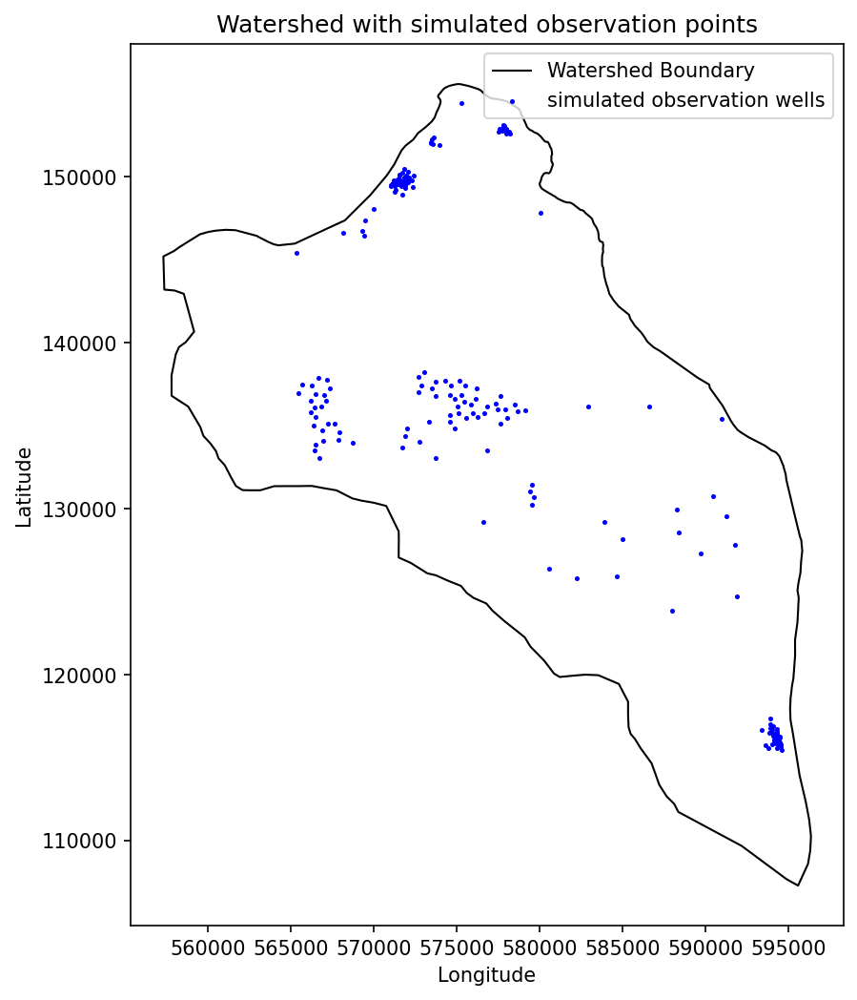

In [37]:
# plot the location of these well in the watershed map
watershed_shp = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp"
watershed_bound = gpd.read_file(watershed_shp)

coord_xy_list = list(zip(sim_pts_df['coord_x'],sim_pts_df['coord_y']))
coord_xy_list = list(set(coord_xy_list))
geometry = [Point(xy) for xy in coord_xy_list]
coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

#plot
fig, ax = plt.subplots(figsize=(12,8))
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')
coord_gdf.plot(ax=ax, color='blue', markersize=2, label='simulated observation wells')

ax.set_title('Watershed with simulated observation points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
#ax.set_xlim(550000, 620000)
plt.legend()

plt.show()

In [38]:
sim_well_list = sim_pts_df.index.tolist()

In [39]:
filtered_well_list = [name.split('_')[1] for name in sim_well_list if name.startswith('Well_')]
sim_unique_well_list = list(set(filtered_well_list))

In [46]:
print(sim_unique_well_list)

['299-W18-27', '299-E33-33', '299-E18-3', '699-13-1A', '699-40-40B', '699-42-12A', '299-E33-28', '399-4-1', '299-E34-7', '199-N-25', '699-42-39B', '299-W19-23', '699-22-35', '399-2-34', '299-W10-19', '299-W10-15', '699-15-15B', '299-W10-18', '399-5-4B', '699-8-25', '699-36-58A', '299-E32-2', '299-E17-14', '299-E34-3', '299-E35-1', '299-W7-7', '299-E25-46', '199-N-41', '199-N-65', '399-4-10', '299-W18-17', '299-E34-12', '299-W19-2', '399-1-18B', '299-E25-37', '299-W6-12', '299-E24-19', '699-41-35', '199-H4-14', '199-N-26', '299-W26-10', '199-N-58', '299-W18-2', '299-W6-8', '299-W22-42', '299-E26-13', '299-W19-28', '299-E32-10', '299-E32-5', '199-N-53', '399-1-14A', '299-W15-24', '199-F7-2', '699-43-41F', '299-E18-1', '299-W7-4', '199-N-30', '399-1-11', '399-2-10', '699-25-34C', '299-W19-30', '399-1-21B', '399-1-15', '299-W19-32', '399-1-18A', '699-33-42', '299-W10-21', '299-E17-18', '399-1-17A', '299-W18-31', '299-E25-36', '699-24-1S', '699-18-21', '299-W18-26', '299-W19-19', '299-E25-3

In [40]:
intersection_wells = list(set(obs_well_list).intersection(sim_unique_well_list))
print('intersected well number: {0}'.format(len(intersection_wells)))
print(intersection_wells)

intersected well number: 80
['399-1-23', '199-H4-15B', '199-K-22', '399-8-5A', '299-E27-12', '399-1-21A', '199-D5-13', '199-D8-5', '399-3-18', '199-N-50', '199-H3-2C', '199-H3-2B', '399-3-37', '399-2-3', '399-4-7', '199-H4-10', '199-K-30', '199-H4-7', '299-W22-44', '399-2-33', '299-W18-23', '399-2-1', '199-H4-12B', '399-1-12', '399-1-1', '399-3-20', '199-H3-2A', '199-K-19', '399-3-10', '199-H4-14', '199-H4-13', '399-2-5', '199-N-26', '299-E26-11', '399-2-2', '399-1-32', '199-F7-2', '399-2-32', '399-1-11', '199-N-34', '399-1-60', '399-1-2', '399-2-10', '399-1-7', '199-H4-8', '299-E26-10', '199-H4-12C', '399-1-21B', '199-H4-11', '399-1-15', '299-E25-40', '299-W18-30', '199-N-14', '399-3-19', '199-N-16', '399-3-21', '399-1-17A', '199-H4-15A', '199-B2-12', '399-3-34', '199-N-72', '199-D5-14', '199-H4-12A', '399-5-1', '399-3-9', '399-1-10A', '399-4-9', '199-H4-9', '199-K-36', '199-N-76', '199-N-71', '399-3-22', '199-H4-18', '199-D8-55', '399-1-16A', '199-H4-17', '199-N-77', '399-2-25', '299

### visualize the location of the intersected wells

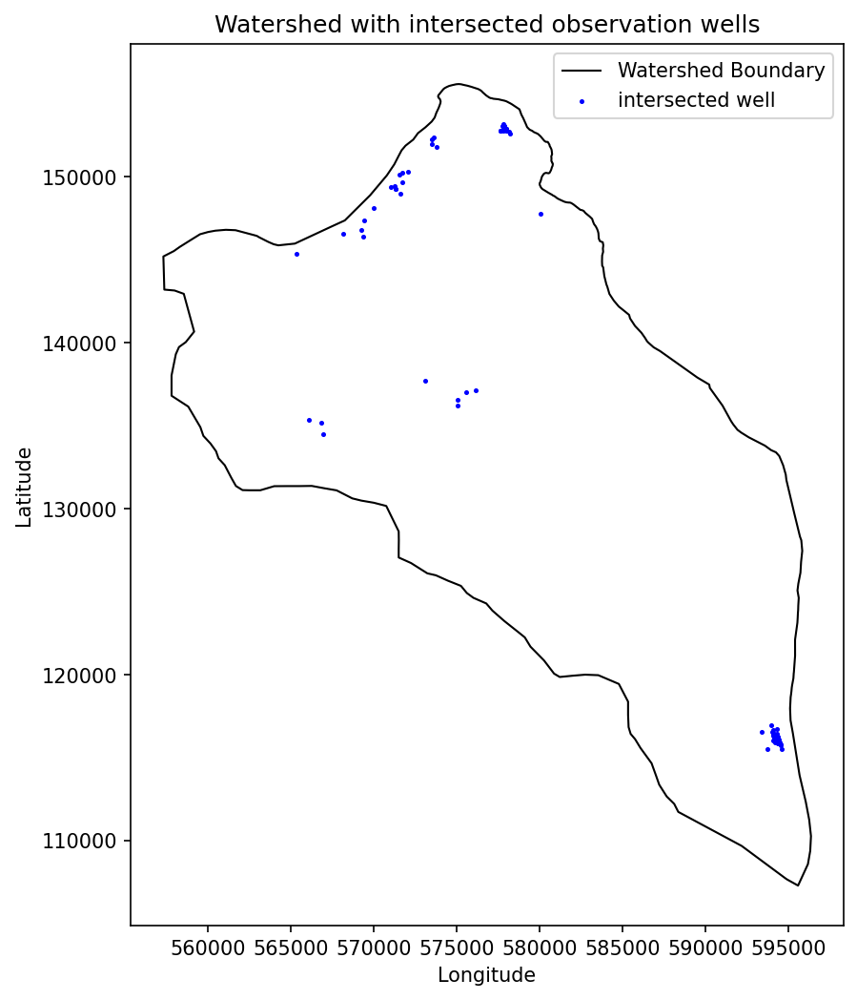

In [44]:
# plot the location of these well in the watershed map
watershed_shp = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp"
watershed_bound = gpd.read_file(watershed_shp)

selected_well_coord = well_coord[well_coord.index.isin(intersection_wells)]
coord_xy_list = list(zip(selected_well_coord['Easting'],selected_well_coord['Northing']))
geometry = [Point(xy) for xy in coord_xy_list]
coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

#plot
fig, ax = plt.subplots(figsize=(12,8))
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')
coord_gdf.plot(ax=ax, color='blue', markersize=2, label='intersected well')

ax.set_title('Watershed with intersected observation wells')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
#ax.set_xlim(550000, 620000)
plt.legend()

plt.show()

### find the nearest mass1 coordinates

In [62]:
fname_mass1_coord = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mass1/Mass1_datum_shift.csv"
mass1_coord = pd.read_csv(fname_mass1_coord, sep=',', skiprows=0, engine='python')
mass1_coord.set_index('quadrant',inplace=True)
mass1_coord = mass1_coord.iloc[34:,:]

In [77]:
xy_iwell_list = []
xy_datum_list = []
datum_index = []
for iwell in intersection_wells:
    well_cds = well_coord.loc[iwell] if iwell in well_coord.index else None
    if well_cds is None:
        print(f"Warning: well '{iwell}' is not found in well_coord.")
        continue
        
    xy_iwell_list.append(well_cds.to_numpy())
    
    euclidean_dist = np.sqrt(((mass1_coord[['easting','northing']]-well_cds.values)**2).sum(axis=1))
    ind = np.argmin(euclidean_dist)   # np.argmin isn't aware of the custom indexing
    xy_datum_list.append(mass1_coord.iloc[ind,0:2].to_numpy())
    datum_index.append(ind+35)
xy_iwell = np.array(xy_iwell_list)
xy_datum = np.array(xy_datum_list)

# check for elements validaity
if any(x > 360 or x < 35 for x in datum_index):
    raise ValueError('Error: Array contains elements larger than 360 or smaller than 35.')
else:
    print('All elements are within the range 35 to 360.')

All elements are within the range 35 to 360.


In [78]:
print(datum_index)
print(mass1_coord.index)

[320, 142, 91, 319, 197, 321, 112, 113, 322, 102, 143, 143, 322, 321, 324, 140, 85, 143, 66, 321, 66, 322, 143, 320, 323, 143, 87, 323, 143, 144, 322, 97, 197, 321, 320, 164, 321, 319, 100, 321, 321, 321, 321, 143, 197, 143, 321, 144, 318, 197, 66, 101, 321, 98, 323, 320, 142, 70, 322, 97, 112, 143, 324, 323, 319, 323, 143, 85, 100, 97, 322, 143, 113, 321, 142, 97, 321, 80, 81]
Index([ 35,  36,  37,  38,  39,  40,  41,  42,  43,  44,
       ...
       351, 352, 353, 354, 355, 356, 357, 358, 359, 360],
      dtype='int64', name='quadrant', length=326)


In [75]:
# remove the well '399-1-1' from the intersected well
intersection_wells.remove('399-1-1')

# the resultant intersection_wells and datum_index should have the same index
print(len(intersection_wells))
print(len(datum_index))

ValueError: list.remove(x): x not in list

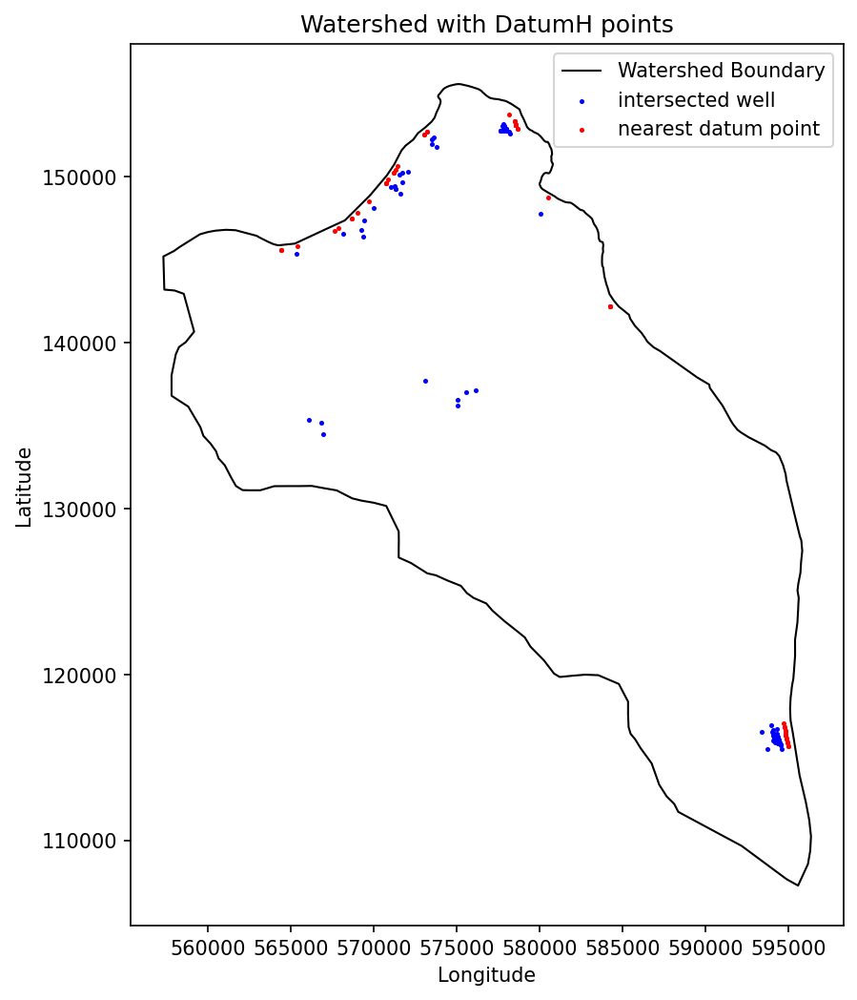

In [79]:
# plot the location of these well in the watershed map
watershed_shp = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp"
watershed_bound = gpd.read_file(watershed_shp)

#fname_mass1_coord = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mass1/Mass1_datum_shift.csv"
#mass1_coord = pd.read_csv(fname_mass1_coord, sep=',', skiprows=0, engine='python')
#mass1_coord.set_index('quadrant',inplace=True)
#mass1_coord = mass1_coord.iloc[35:-1,:]

#coord_xy_iwell = list(zip(mass1_coord['easting'],mass1_coord['northing']))
geometry = [Point(xy) for xy in xy_iwell_list]
iwell_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

geometry = [Point(xy) for xy in xy_datum_list]
datum_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

#plot
fig, ax = plt.subplots(figsize=(12,8))
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

iwell_coord_gdf.plot(ax=ax, color='blue', markersize=2, label='intersected well')
datum_coord_gdf.plot(ax=ax, color='red', markersize=2, label='nearest datum point')

ax.set_title('Watershed with DatumH points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
#ax.set_xlim(550000, 620000)
plt.legend()

plt.show()

In [51]:
print('number of well: {0}'.format(intersection_wells))
print(intersection_wells)

number of well: ['399-1-23', '199-H4-15B', '199-K-22', '399-8-5A', '299-E27-12', '399-1-21A', '199-D5-13', '199-D8-5', '399-3-18', '199-N-50', '199-H3-2C', '199-H3-2B', '399-3-37', '399-2-3', '399-4-7', '199-H4-10', '199-K-30', '199-H4-7', '299-W22-44', '399-2-33', '299-W18-23', '399-2-1', '199-H4-12B', '399-1-12', '399-3-20', '199-H3-2A', '199-K-19', '399-3-10', '199-H4-14', '199-H4-13', '399-2-5', '199-N-26', '299-E26-11', '399-2-2', '399-1-32', '199-F7-2', '399-2-32', '399-1-11', '199-N-34', '399-1-60', '399-1-2', '399-2-10', '399-1-7', '199-H4-8', '299-E26-10', '199-H4-12C', '399-1-21B', '199-H4-11', '399-1-15', '299-E25-40', '299-W18-30', '199-N-14', '399-3-19', '199-N-16', '399-3-21', '399-1-17A', '199-H4-15A', '199-B2-12', '399-3-34', '199-N-72', '199-D5-14', '199-H4-12A', '399-5-1', '399-3-9', '399-1-10A', '399-4-9', '199-H4-9', '199-K-36', '199-N-76', '199-N-71', '399-3-22', '199-H4-18', '199-D8-55', '399-1-16A', '199-H4-17', '199-N-77', '399-2-25', '299-E33-34', '199-K-31']
[

2024-12-17 01:05:32,940 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
2024-12-17 01:05:33,706 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
2024-12-17 01:05:34,401 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
2024-12-17 01:05:35,091 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
2024-12-17 01:05:35,785 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an under

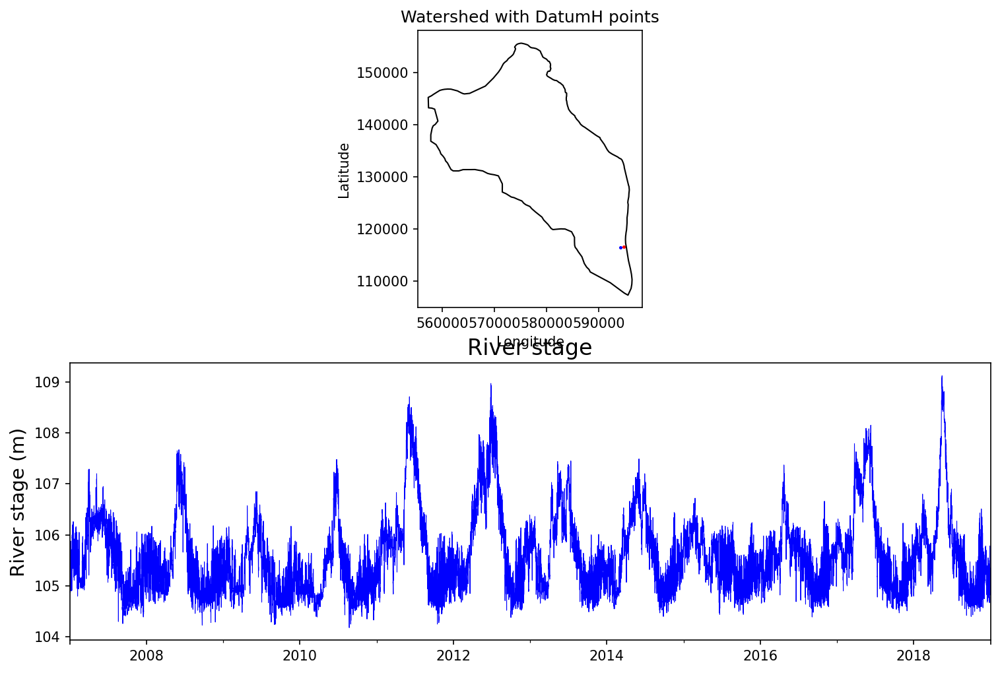

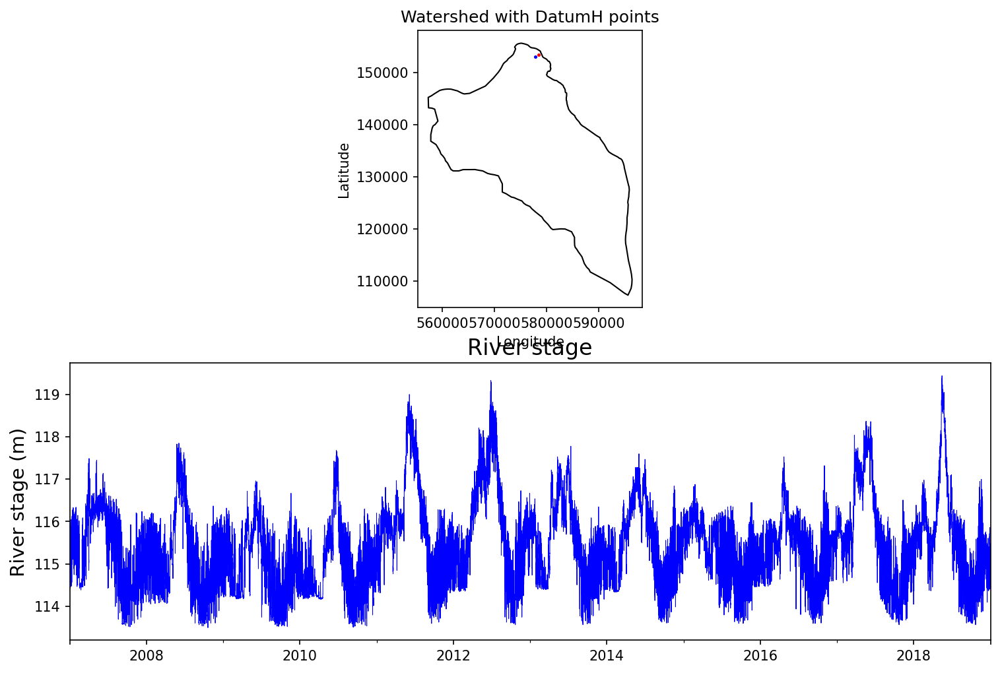

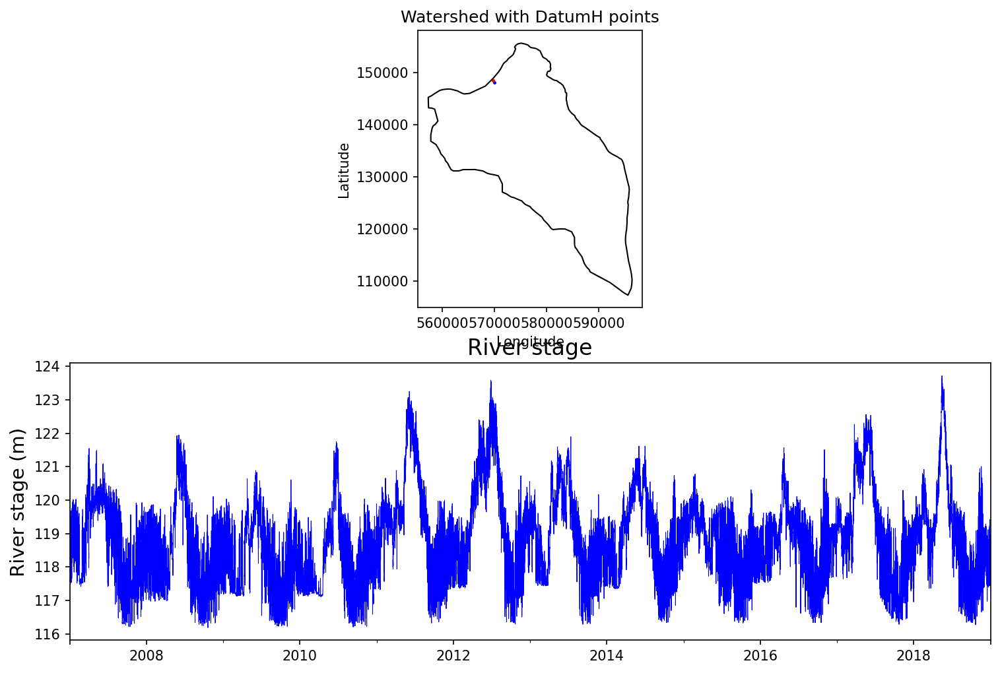

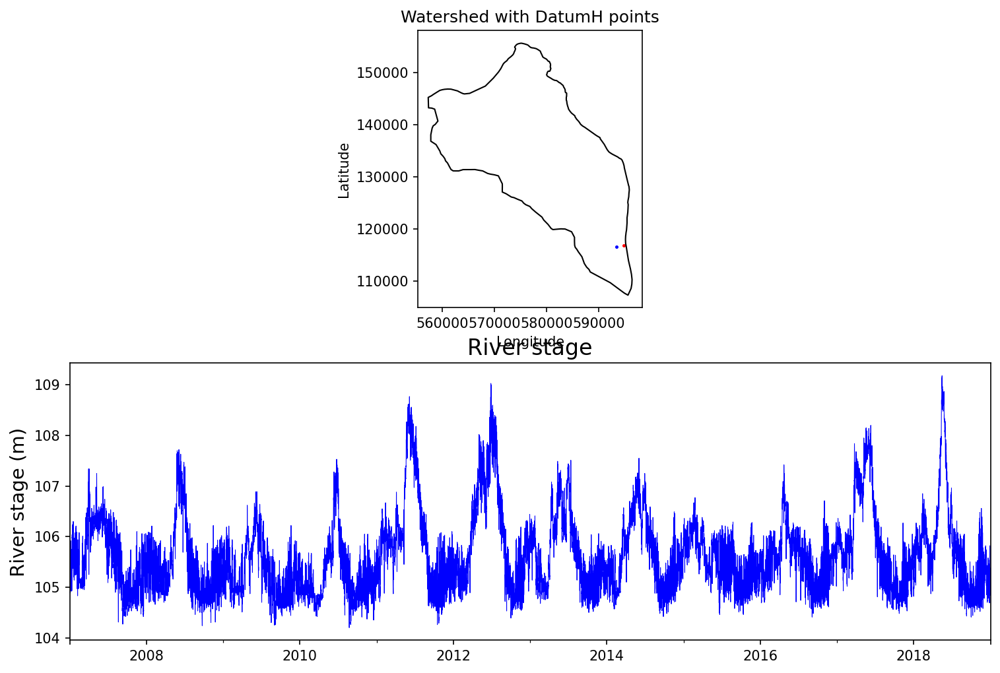

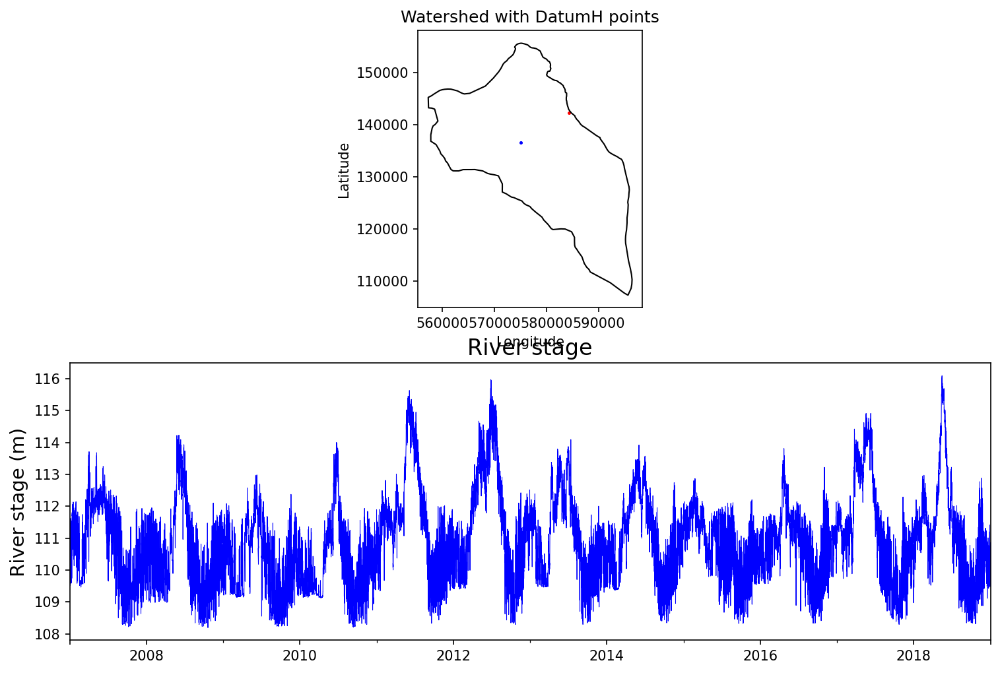

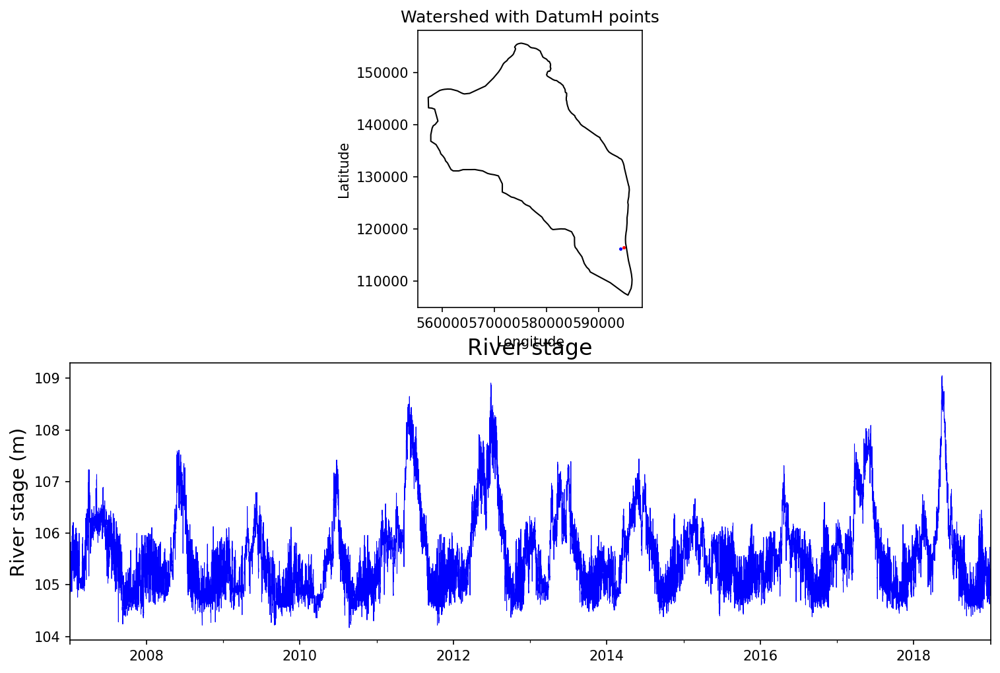

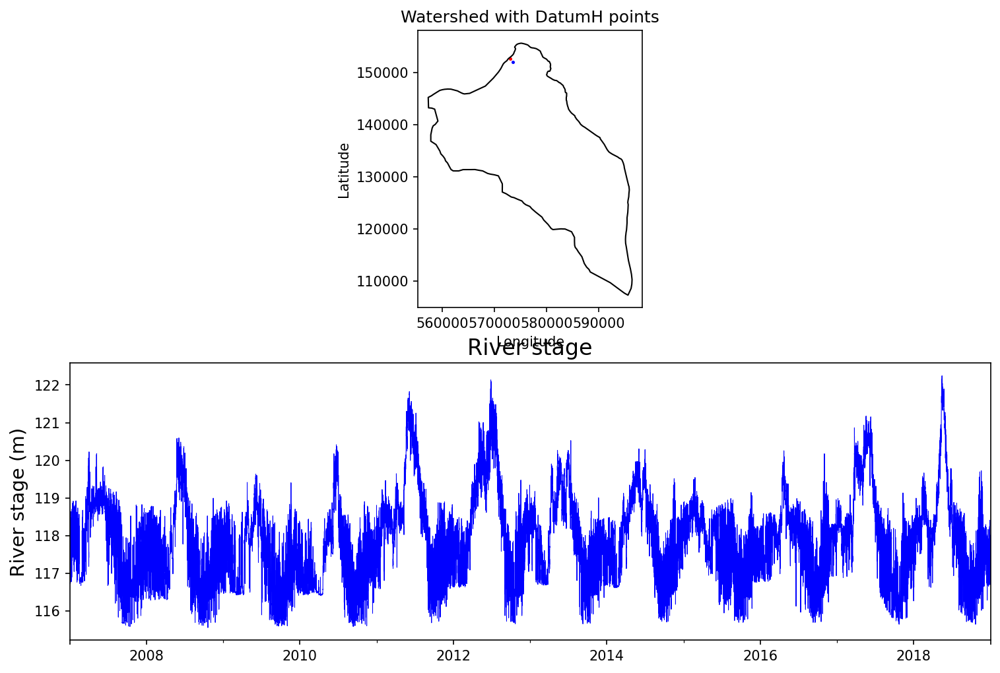

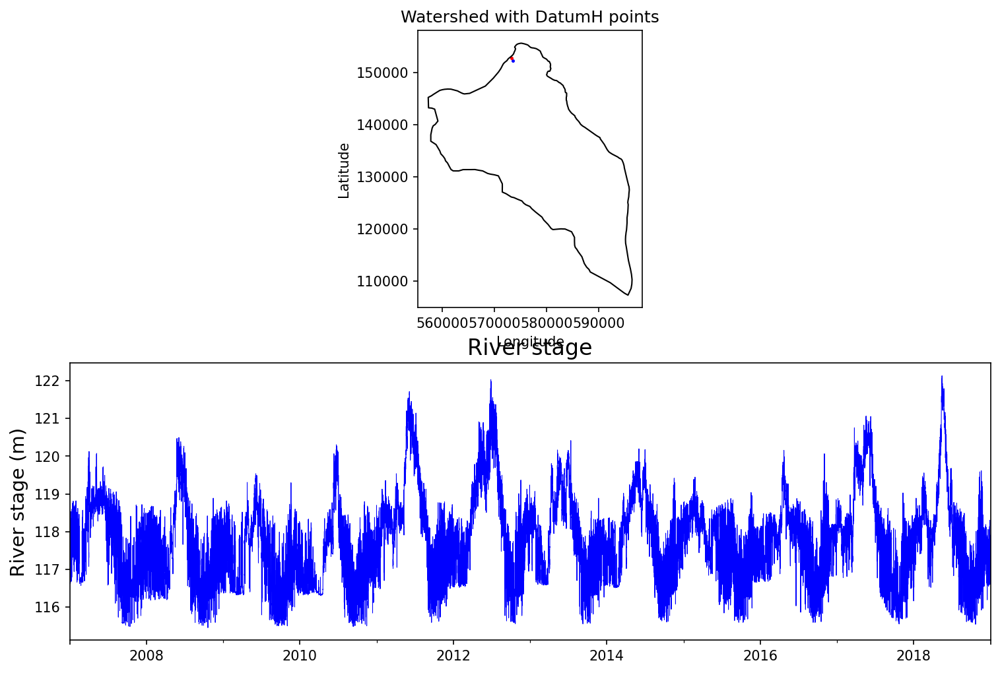

In [80]:
fdir_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'

for index, iwell in enumerate(intersection_wells[0]):
    datum_id = datum_index[index]
    fname_river_stage = 'DatumH_River_' + str(datum_id) + '.txt'
    f_river_stage = fdir_river_stage + fname_river_stage
    river_stage = pd.read_csv(f_river_stage, header = None, sep = " ", names = ['dt', 'Easting', 'Northing', 'wl'])
    river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
    river_stage.set_index('datetime', drop=False, inplace=True)
 
    geometry = [Point(xy_iwell_list[index])]
    iwell_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

    geometry = [Point(xy_datum_list[index])]
    datum_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

    #plot
    fig, ax = plt.subplots(2,1,figsize=(12,8))
    watershed_bound.boundary.plot(ax=ax[0], color='black', linewidth=1, label='Watershed Boundary')

    iwell_coord_gdf.plot(ax=ax[0], color='blue', markersize=2, label='intersected well')
    datum_coord_gdf.plot(ax=ax[0], color='red', markersize=2, label='nearest datum point')

    ax[0].set_title('Watershed with DatumH points')
    ax[0].set_xlabel('Longitude')
    ax[0].set_ylabel('Latitude')
    #ax.set_xlim(550000, 620000)
    plt.legend()
    
    
    river_stage.plot(y='wl', color = 'blue', ax=ax[1], lw=0.5, zorder=1)

#     ax.scatter(river_stage.loc[itime, 'datetime'], river_stage.loc[itime, 'wl'], 
#                     facecolors = 'red', edgecolors= 'black', s = 30, alpha = 1,zorder=2)

    ax[1].set_ylabel('River stage (m)', fontsize = 14)
    ax[1].set_xlabel('')
    ax[1].set_title('River stage', fontsize=16)
    ax[1].get_legend().remove()
    ax[1].set_xlim(['01/01/2007','01/01/2019'])  

#    plt.show()

In [ ]:


fdir_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'
fname_river_stage = 'DatumH_River_321.txt'    # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

# for itime in tqdm(river_stage.index[::120]):

fig, ax = plt.subplots(1,1, figsize=(8,4))

river_stage.plot(y='wl', color = 'blue', ax=ax, lw=0.5, zorder=1)

#     ax.scatter(river_stage.loc[itime, 'datetime'], river_stage.loc[itime, 'wl'], 
#                     facecolors = 'red', edgecolors= 'black', s = 30, alpha = 1,zorder=2)

ax.set_ylabel('River stage (m)', fontsize = 14)
ax.set_xlabel('')
ax.set_title('River stage', fontsize=16)
ax.get_legend().remove()
ax.set_xlim(['01/01/2007','01/01/2019'])  

# plot simulation water table vs observation water table

### import simulation data (isotropic perm)

In [54]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-isotro_perm/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', "rb") as f:
    iso_perm_well_data_df = pickle.load(f)

### import simulation data (anisotropic perm except basalt)

In [55]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-aniso_perm_except_basalt/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', "rb") as f:
    aniso_perm_except_basalt_well_data_df = pickle.load(f)

### import simulation data (anisotropic perm only alluvium)

In [56]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-aniso_perm_only_alluvium/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', "rb") as f:
    aniso_perm_only_alluvium_well_data_df = pickle.load(f)

### import obs well coordinations

In [57]:
## import observation points 
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR_perm/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-obs_pts_df.xz', "rb") as f:
    obs_pts_df = pickle.load(f)

In [58]:
def model_comparison(iwell_name, iso_perm_well_data_df, aniso_perm_except_basalt_well_data_df, aniso_perm_only_alluvium_well_data_df, well_valid):
    iwell = 'Well_'+iwell_name
    #-------isotropic perm model------------------
    iso_isimu_head = iso_perm_well_data_df[iwell, 'Liquid Pressure [Pa]'].copy().sort_index()
    iso_isimu_head = (iso_isimu_head - P_atm) / rho / g_const

    iso_isimu_head.dropna(axis = 1, inplace = True)

    for i in iso_isimu_head.columns:
        iso_isimu_head.loc[:, i] = iso_isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in iso_isimu_head.index])

    iso_isimu_head['DateTime'] = pd.to_datetime(simu_time)
    iso_isimu_head.set_index('DateTime', inplace=True)

    #----------anisotropic perm model (except basalt)-----------------
    aniso_except_basalt_isimu_head = aniso_perm_except_basalt_well_data_df[iwell, 'Liquid Pressure [Pa]'].copy().sort_index()
    aniso_except_basalt_isimu_head = (aniso_except_basalt_isimu_head - P_atm) / rho / g_const

    aniso_except_basalt_isimu_head.dropna(axis = 1, inplace = True)

    for i in aniso_except_basalt_isimu_head.columns:
        aniso_except_basalt_isimu_head.loc[:, i] = aniso_except_basalt_isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in aniso_except_basalt_isimu_head.index])

    aniso_except_basalt_isimu_head['DateTime'] = pd.to_datetime(simu_time)
    aniso_except_basalt_isimu_head.set_index('DateTime', inplace=True)

    #----------anisotropic perm model (only alluvium)-----------------
    aniso_only_alluvium_isimu_head = aniso_perm_only_alluvium_well_data_df[iwell, 'Liquid Pressure [Pa]'].copy().sort_index()
    aniso_only_alluvium_isimu_head = (aniso_only_alluvium_isimu_head - P_atm) / rho / g_const

    aniso_only_alluvium_isimu_head.dropna(axis = 1, inplace = True)

    for i in aniso_only_alluvium_isimu_head.columns:
        aniso_only_alluvium_isimu_head.loc[:, i] = aniso_only_alluvium_isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in aniso_only_alluvium_isimu_head.index])

    aniso_only_alluvium_isimu_head['DateTime'] = pd.to_datetime(simu_time)
    aniso_only_alluvium_isimu_head.set_index('DateTime', inplace=True)

    #----------observation data input------------------------------
    iobs_head =  well_valid[well_valid['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head['DateTime'] = pd.to_datetime(iobs_head['DateTime'])
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    return iobs_head, iso_isimu_head, aniso_except_basalt_isimu_head, aniso_only_alluvium_isimu_head 

In [125]:
# pre-check the wells
print(intersection_wells)

['399-1-23', '199-H4-15B', '199-K-22', '399-8-5A', '299-E27-12', '399-1-21A', '199-D5-13', '199-D8-5', '399-3-18', '199-N-50', '199-H3-2C', '199-H3-2B', '399-3-37', '399-2-3', '399-4-7', '199-H4-10', '199-K-30', '199-H4-7', '299-W22-44', '399-2-33', '299-W18-23', '399-2-1', '199-H4-12B', '399-1-12', '399-3-20', '199-H3-2A', '199-K-19', '399-3-10', '199-H4-14', '199-H4-13', '399-2-5', '199-N-26', '299-E26-11', '399-2-2', '399-1-32', '199-F7-2', '399-2-32', '399-1-11', '199-N-34', '399-1-60', '399-1-2', '399-2-10', '399-1-7', '199-H4-8', '299-E26-10', '199-H4-12C', '399-1-21B', '199-H4-11', '399-1-15', '299-E25-40', '299-W18-30', '199-N-14', '399-3-19', '199-N-16', '399-3-21', '399-1-17A', '199-H4-15A', '199-B2-12', '399-3-34', '199-N-72', '199-D5-14', '199-H4-12A', '399-5-1', '399-3-9', '399-1-10A', '399-4-9', '199-H4-9', '199-K-36', '199-N-76', '199-N-71', '399-3-22', '199-H4-18', '199-D8-55', '399-1-16A', '199-H4-17', '199-N-77', '399-2-25', '299-E33-34', '199-K-31']


2024-12-17 08:45:32,584 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:0, well name:399-1-23
isotropic perm model: {'RMSE': 0.14647825947562396}, anisotropic perm model(except basalt): {'RMSE': 0.2369025041476349}, anisotropic perm model (only alluvium): {'RMSE': 0.16201671819280256}


2024-12-17 08:45:36,661 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:1, well name:199-H4-15B
isotropic perm model: {'RMSE': 0.30985633812661256}, anisotropic perm model(except basalt): {'RMSE': 1.0539857514854238}, anisotropic perm model (only alluvium): {'RMSE': 0.32076246725994806}


2024-12-17 08:45:40,419 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:2, well name:199-K-22
isotropic perm model: {'RMSE': 0.7781138398429435}, anisotropic perm model(except basalt): {'RMSE': 0.83362370671902}, anisotropic perm model (only alluvium): {'RMSE': 0.7858274621670586}


2024-12-17 08:45:44,330 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:3, well name:399-8-5A
isotropic perm model: {'RMSE': 0.0895747512721362}, anisotropic perm model(except basalt): {'RMSE': 0.1502403997966144}, anisotropic perm model (only alluvium): {'RMSE': 0.10160104726905902}


2024-12-17 08:45:46,669 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:4, well name:299-E27-12
isotropic perm model: {'RMSE': 1.9819498979647356}, anisotropic perm model(except basalt): {'RMSE': 1.830836300017444}, anisotropic perm model (only alluvium): {'RMSE': 1.8308317542823473}


2024-12-17 08:45:51,105 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:5, well name:399-1-21A
isotropic perm model: {'RMSE': 0.14766772091079178}, anisotropic perm model(except basalt): {'RMSE': 0.24308729017878128}, anisotropic perm model (only alluvium): {'RMSE': 0.15687829180060445}


2024-12-17 08:45:53,355 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:6, well name:199-D5-13
isotropic perm model: {'RMSE': 0.45407571851098666}, anisotropic perm model(except basalt): {'RMSE': 0.36840670758286975}, anisotropic perm model (only alluvium): {'RMSE': 0.4858336619337681}


2024-12-17 08:45:55,935 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:7, well name:199-D8-5
isotropic perm model: {'RMSE': 0.6568436647202608}, anisotropic perm model(except basalt): {'RMSE': 0.49003338529504165}, anisotropic perm model (only alluvium): {'RMSE': 0.692982272667897}


2024-12-17 08:46:00,559 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:8, well name:399-3-18
isotropic perm model: {'RMSE': 0.1318216284234106}, anisotropic perm model(except basalt): {'RMSE': 0.241185965694866}, anisotropic perm model (only alluvium): {'RMSE': 0.1355055415699869}


2024-12-17 08:46:04,507 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:9, well name:199-N-50
isotropic perm model: {'RMSE': 0.7970242747778553}, anisotropic perm model(except basalt): {'RMSE': 0.7920136428573332}, anisotropic perm model (only alluvium): {'RMSE': 0.7266224698664666}


2024-12-17 08:46:07,111 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:10, well name:199-H3-2C
isotropic perm model: {'RMSE': 0.661419318753226}, anisotropic perm model(except basalt): {'RMSE': 0.43082400913790764}, anisotropic perm model (only alluvium): {'RMSE': 0.6457142677036528}


2024-12-17 08:46:10,973 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:11, well name:199-H3-2B
isotropic perm model: {'RMSE': 0.8180667021924719}, anisotropic perm model(except basalt): {'RMSE': 0.7977080689235317}, anisotropic perm model (only alluvium): {'RMSE': 0.8234828756579479}


2024-12-17 08:46:14,224 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:12, well name:399-3-37
isotropic perm model: {'RMSE': 0.1750869145561024}, anisotropic perm model(except basalt): {'RMSE': 0.27342818860714063}, anisotropic perm model (only alluvium): {'RMSE': 0.1877553956707796}


2024-12-17 08:46:18,381 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:13, well name:399-2-3
isotropic perm model: {'RMSE': 0.12742052079403507}, anisotropic perm model(except basalt): {'RMSE': 0.23403229587893778}, anisotropic perm model (only alluvium): {'RMSE': 0.1535781551406526}


2024-12-17 08:46:22,186 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:14, well name:399-4-7
isotropic perm model: {'RMSE': 0.11360016942064495}, anisotropic perm model(except basalt): {'RMSE': 0.2693795416461449}, anisotropic perm model (only alluvium): {'RMSE': 0.11318058822526525}


2024-12-17 08:46:25,919 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:15, well name:199-H4-10
isotropic perm model: {'RMSE': 0.21433963192716646}, anisotropic perm model(except basalt): {'RMSE': 0.8811744764768521}, anisotropic perm model (only alluvium): {'RMSE': 0.22826527817007805}


2024-12-17 08:46:28,575 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:16, well name:199-K-30
isotropic perm model: {'RMSE': 1.4274137958604405}, anisotropic perm model(except basalt): {'RMSE': 1.4595075370363737}, anisotropic perm model (only alluvium): {'RMSE': 1.4708977049383827}


2024-12-17 08:46:31,076 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:17, well name:199-H4-7
isotropic perm model: {'RMSE': 0.589026993083107}, anisotropic perm model(except basalt): {'RMSE': 0.4444317198214858}, anisotropic perm model (only alluvium): {'RMSE': 0.5715871998395271}


2024-12-17 08:46:33,619 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:18, well name:299-W22-44
isotropic perm model: {'RMSE': 2.771826080279808}, anisotropic perm model(except basalt): {'RMSE': 0.8039462467083089}, anisotropic perm model (only alluvium): {'RMSE': 0.8039474372437166}


2024-12-17 08:46:36,937 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:19, well name:399-2-33
isotropic perm model: {'RMSE': 0.17393568227083628}, anisotropic perm model(except basalt): {'RMSE': 0.2926974111157595}, anisotropic perm model (only alluvium): {'RMSE': 0.17594998431269251}


/tmp/ipykernel_1252087/858719858.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(3,1,figsize=(12,8))
2024-12-17 08:46:39,349 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:20, well name:299-W18-23
isotropic perm model: {'RMSE': 10.909464715616705}, anisotropic perm model(except basalt): {'RMSE': 8.12019116115488}, anisotropic perm model (only alluvium): {'RMSE': 8.120191140462284}


2024-12-17 08:46:43,006 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:21, well name:399-2-1
isotropic perm model: {'RMSE': 0.15146663409383876}, anisotropic perm model(except basalt): {'RMSE': 0.24965864651644143}, anisotropic perm model (only alluvium): {'RMSE': 0.17589035039544051}


2024-12-17 08:46:46,534 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:22, well name:199-H4-12B
isotropic perm model: {'RMSE': 0.35894509519006484}, anisotropic perm model(except basalt): {'RMSE': 0.9128416781336611}, anisotropic perm model (only alluvium): {'RMSE': 0.34592132365001343}


2024-12-17 08:46:50,550 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:23, well name:399-1-12
isotropic perm model: {'RMSE': 0.12740490389239917}, anisotropic perm model(except basalt): {'RMSE': 0.22164741538774876}, anisotropic perm model (only alluvium): {'RMSE': 0.1376411480720189}


2024-12-17 08:46:55,215 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:24, well name:399-3-20
isotropic perm model: {'RMSE': 0.12829494992931556}, anisotropic perm model(except basalt): {'RMSE': 0.2443780104073016}, anisotropic perm model (only alluvium): {'RMSE': 0.12964708439036668}


2024-12-17 08:46:57,404 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The union index is empty, skipping metric calculations for 199-H3-2A
well index:25, well name:199-H3-2A
isotropic perm model: None, anisotropic perm model(except basalt): None, anisotropic perm model (only alluvium): None


2024-12-17 08:47:00,880 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:26, well name:199-K-19
isotropic perm model: {'RMSE': 0.6837969874878519}, anisotropic perm model(except basalt): {'RMSE': 0.6634407533360411}, anisotropic perm model (only alluvium): {'RMSE': 0.6924929283042459}


2024-12-17 08:47:07,394 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:27, well name:399-3-10
isotropic perm model: {'RMSE': 0.07915887149051758}, anisotropic perm model(except basalt): {'RMSE': 0.17256331593985652}, anisotropic perm model (only alluvium): {'RMSE': 0.08299150984631601}


2024-12-17 08:47:09,987 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:28, well name:199-H4-14
isotropic perm model: {'RMSE': 4.64912056783154}, anisotropic perm model(except basalt): {'RMSE': 4.40938769555052}, anisotropic perm model (only alluvium): {'RMSE': 4.610790766254755}


2024-12-17 08:47:12,700 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:29, well name:199-H4-13
isotropic perm model: {'RMSE': 0.19972260863886837}, anisotropic perm model(except basalt): {'RMSE': 1.3329660757847281}, anisotropic perm model (only alluvium): {'RMSE': 0.12062944813038264}


2024-12-17 08:47:16,813 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:30, well name:399-2-5
isotropic perm model: {'RMSE': 0.15505837933770508}, anisotropic perm model(except basalt): {'RMSE': 0.26822937743142616}, anisotropic perm model (only alluvium): {'RMSE': 0.1534177013055208}


2024-12-17 08:47:19,217 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:31, well name:199-N-26
isotropic perm model: {'RMSE': 0.1429775071597953}, anisotropic perm model(except basalt): {'RMSE': 0.19540126305072897}, anisotropic perm model (only alluvium): {'RMSE': 0.13649389821326058}


2024-12-17 08:47:21,379 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:32, well name:299-E26-11
isotropic perm model: {'RMSE': 2.872132085910135}, anisotropic perm model(except basalt): {'RMSE': 2.865840551188389}, anisotropic perm model (only alluvium): {'RMSE': 2.865840551188389}


2024-12-17 08:47:25,430 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:33, well name:399-2-2
isotropic perm model: {'RMSE': 0.13087748906254637}, anisotropic perm model(except basalt): {'RMSE': 0.23230955298241632}, anisotropic perm model (only alluvium): {'RMSE': 0.16411157375828028}


2024-12-17 08:47:28,824 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:34, well name:399-1-32
isotropic perm model: {'RMSE': 0.18857415282756673}, anisotropic perm model(except basalt): {'RMSE': 0.2996821976639778}, anisotropic perm model (only alluvium): {'RMSE': 0.20249261953149938}


2024-12-17 08:47:31,604 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:35, well name:199-F7-2
isotropic perm model: {'RMSE': 0.8512118392021495}, anisotropic perm model(except basalt): {'RMSE': 1.8608466938731765}, anisotropic perm model (only alluvium): {'RMSE': 0.9002910485058276}


2024-12-17 08:47:34,834 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:36, well name:399-2-32
isotropic perm model: {'RMSE': 0.1575902389009067}, anisotropic perm model(except basalt): {'RMSE': 0.23886097176993112}, anisotropic perm model (only alluvium): {'RMSE': 0.16466182168741816}


2024-12-17 08:47:39,376 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:37, well name:399-1-11
isotropic perm model: {'RMSE': 0.07834191207167077}, anisotropic perm model(except basalt): {'RMSE': 0.15844372395030726}, anisotropic perm model (only alluvium): {'RMSE': 0.11124016980289879}


2024-12-17 08:47:42,977 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:38, well name:199-N-34
isotropic perm model: {'RMSE': 0.5600946166570725}, anisotropic perm model(except basalt): {'RMSE': 0.5247559144369941}, anisotropic perm model (only alluvium): {'RMSE': 0.43975727360319045}


2024-12-17 08:47:46,360 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:39, well name:399-1-60
isotropic perm model: {'RMSE': 0.2185737468370837}, anisotropic perm model(except basalt): {'RMSE': 0.3203781131002628}, anisotropic perm model (only alluvium): {'RMSE': 0.2150139655257877}


2024-12-17 08:47:50,343 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:40, well name:399-1-2
isotropic perm model: {'RMSE': 0.16162597875086715}, anisotropic perm model(except basalt): {'RMSE': 0.2492475003291291}, anisotropic perm model (only alluvium): {'RMSE': 0.16835708765378962}


2024-12-17 08:47:53,548 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:41, well name:399-2-10
isotropic perm model: {'RMSE': 0.13759901561604293}, anisotropic perm model(except basalt): {'RMSE': 0.24101307911199307}, anisotropic perm model (only alluvium): {'RMSE': 0.14895202084550288}


2024-12-17 08:47:57,243 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:42, well name:399-1-7
isotropic perm model: {'RMSE': 0.1141321304095059}, anisotropic perm model(except basalt): {'RMSE': 0.21462723923571767}, anisotropic perm model (only alluvium): {'RMSE': 0.14147237732550366}


2024-12-17 08:48:00,959 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:43, well name:199-H4-8
isotropic perm model: {'RMSE': 0.3835857675809473}, anisotropic perm model(except basalt): {'RMSE': 0.8120329885577711}, anisotropic perm model (only alluvium): {'RMSE': 0.3982248696639066}


2024-12-17 08:48:03,144 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:44, well name:299-E26-10
isotropic perm model: {'RMSE': 1.7211365295728929}, anisotropic perm model(except basalt): {'RMSE': 0.9269234383618321}, anisotropic perm model (only alluvium): {'RMSE': 0.9269236315451694}


2024-12-17 08:48:05,808 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:45, well name:199-H4-12C
isotropic perm model: {'RMSE': 0.21184380437854725}, anisotropic perm model(except basalt): {'RMSE': 0.514190719179279}, anisotropic perm model (only alluvium): {'RMSE': 0.17474467483773756}


2024-12-17 08:48:08,772 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:46, well name:399-1-21B
isotropic perm model: {'RMSE': 0.13524204080789426}, anisotropic perm model(except basalt): {'RMSE': 0.23938706979222082}, anisotropic perm model (only alluvium): {'RMSE': 0.1322561001578495}


2024-12-17 08:48:12,239 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:47, well name:199-H4-11
isotropic perm model: {'RMSE': 0.5491696780527423}, anisotropic perm model(except basalt): {'RMSE': 1.2571104910360722}, anisotropic perm model (only alluvium): {'RMSE': 0.5325329713151172}


2024-12-17 08:48:16,066 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:48, well name:399-1-15
isotropic perm model: {'RMSE': 0.09774724063921418}, anisotropic perm model(except basalt): {'RMSE': 0.12845791245334923}, anisotropic perm model (only alluvium): {'RMSE': 0.14029429864767182}


2024-12-17 08:48:18,391 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:49, well name:299-E25-40
isotropic perm model: {'RMSE': 0.9005816112041685}, anisotropic perm model(except basalt): {'RMSE': 2.562364379507065}, anisotropic perm model (only alluvium): {'RMSE': 2.5623611254587595}


2024-12-17 08:48:20,519 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The union index is empty, skipping metric calculations for 299-W18-30
well index:50, well name:299-W18-30
isotropic perm model: None, anisotropic perm model(except basalt): None, anisotropic perm model (only alluvium): None


2024-12-17 08:48:24,205 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:51, well name:199-N-14
isotropic perm model: {'RMSE': 1.0339622441690706}, anisotropic perm model(except basalt): {'RMSE': 0.8385616877464429}, anisotropic perm model (only alluvium): {'RMSE': 1.0044058154249687}


/tmp/ipykernel_1252087/3496646777.py:49: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  iobs_head['DateTime'] = pd.to_datetime(iobs_head['DateTime'])
2024-12-17 08:48:41,939 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:52, well name:399-3-19
isotropic perm model: {'RMSE': 0.12666005954949686}, anisotropic perm model(except basalt): {'RMSE': 0.22857895078491755}, anisotropic perm model (only alluvium): {'RMSE': 0.1254889591468492}


2024-12-17 08:48:44,066 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The union index is empty, skipping metric calculations for 199-N-16
well index:53, well name:199-N-16
isotropic perm model: None, anisotropic perm model(except basalt): None, anisotropic perm model (only alluvium): None


2024-12-17 08:48:48,206 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:54, well name:399-3-21
isotropic perm model: {'RMSE': 0.12061140710628088}, anisotropic perm model(except basalt): {'RMSE': 0.25022988630205634}, anisotropic perm model (only alluvium): {'RMSE': 0.110269531411622}


2024-12-17 08:48:51,982 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:55, well name:399-1-17A
isotropic perm model: {'RMSE': 0.15599409628910013}, anisotropic perm model(except basalt): {'RMSE': 0.2591362250844245}, anisotropic perm model (only alluvium): {'RMSE': 0.1688655803862688}


2024-12-17 08:48:54,563 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:56, well name:199-H4-15A
isotropic perm model: {'RMSE': 0.9167533360876818}, anisotropic perm model(except basalt): {'RMSE': 1.0612970163099087}, anisotropic perm model (only alluvium): {'RMSE': 0.930491773723746}


2024-12-17 08:48:57,192 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:57, well name:199-B2-12
isotropic perm model: {'RMSE': 0.45143989752485103}, anisotropic perm model(except basalt): {'RMSE': 0.4708157593060449}, anisotropic perm model (only alluvium): {'RMSE': 0.4503774717389082}


2024-12-17 08:49:00,638 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:58, well name:399-3-34
isotropic perm model: {'RMSE': 0.2003867892430223}, anisotropic perm model(except basalt): {'RMSE': 0.3009508070616007}, anisotropic perm model (only alluvium): {'RMSE': 0.2001883465709186}


2024-12-17 08:49:04,071 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:59, well name:199-N-72
isotropic perm model: {'RMSE': 0.3458368598722257}, anisotropic perm model(except basalt): {'RMSE': 0.3196405280876849}, anisotropic perm model (only alluvium): {'RMSE': 0.3412265079286318}


2024-12-17 08:49:07,130 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:60, well name:199-D5-14
isotropic perm model: {'RMSE': 0.9735784777994518}, anisotropic perm model(except basalt): {'RMSE': 1.1552913818095467}, anisotropic perm model (only alluvium): {'RMSE': 0.9352153987735985}


2024-12-17 08:49:09,712 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:61, well name:199-H4-12A
isotropic perm model: {'RMSE': 0.6091486196973656}, anisotropic perm model(except basalt): {'RMSE': 1.1427175811356383}, anisotropic perm model (only alluvium): {'RMSE': 0.6335816309160499}


/tmp/ipykernel_1252087/3496646777.py:49: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  iobs_head['DateTime'] = pd.to_datetime(iobs_head['DateTime'])
2024-12-17 08:49:18,644 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:62, well name:399-5-1
isotropic perm model: {'RMSE': 0.23114327574044133}, anisotropic perm model(except basalt): {'RMSE': 0.3472663695069976}, anisotropic perm model (only alluvium): {'RMSE': 0.19259140138180614}


2024-12-17 08:49:21,205 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:63, well name:399-3-9
isotropic perm model: {'RMSE': 0.11118227057770122}, anisotropic perm model(except basalt): {'RMSE': 0.20107874823956748}, anisotropic perm model (only alluvium): {'RMSE': 0.10809125588649923}


2024-12-17 08:49:25,734 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:64, well name:399-1-10A
isotropic perm model: {'RMSE': 0.08471886548272203}, anisotropic perm model(except basalt): {'RMSE': 0.18989923032173223}, anisotropic perm model (only alluvium): {'RMSE': 0.15084304371325116}


2024-12-17 08:49:29,274 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:65, well name:399-4-9
isotropic perm model: {'RMSE': 0.1371986230478147}, anisotropic perm model(except basalt): {'RMSE': 0.27732516097474513}, anisotropic perm model (only alluvium): {'RMSE': 0.12103886670599642}


2024-12-17 08:49:32,454 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:66, well name:199-H4-9
isotropic perm model: {'RMSE': 0.2528811177675856}, anisotropic perm model(except basalt): {'RMSE': 0.6442062046823844}, anisotropic perm model (only alluvium): {'RMSE': 0.2530861561560402}


2024-12-17 08:49:34,590 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:67, well name:199-K-36
isotropic perm model: {'RMSE': 0.6941239579373822}, anisotropic perm model(except basalt): {'RMSE': 0.790773482876788}, anisotropic perm model (only alluvium): {'RMSE': 0.8670996884588721}


2024-12-17 08:49:38,216 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:68, well name:199-N-76
isotropic perm model: {'RMSE': 0.25950796965864953}, anisotropic perm model(except basalt): {'RMSE': 0.44459413560196603}, anisotropic perm model (only alluvium): {'RMSE': 0.2524115771027696}


2024-12-17 08:49:41,249 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:69, well name:199-N-71
isotropic perm model: {'RMSE': 0.642887240044299}, anisotropic perm model(except basalt): {'RMSE': 0.6076949664189726}, anisotropic perm model (only alluvium): {'RMSE': 0.7018885832632231}


2024-12-17 08:49:45,350 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:70, well name:399-3-22
isotropic perm model: {'RMSE': 0.14650483688693414}, anisotropic perm model(except basalt): {'RMSE': 0.2608728640077036}, anisotropic perm model (only alluvium): {'RMSE': 0.13164785999461034}


2024-12-17 08:49:47,989 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:71, well name:199-H4-18
isotropic perm model: {'RMSE': 4.073560601502778}, anisotropic perm model(except basalt): {'RMSE': 3.604258259999791}, anisotropic perm model (only alluvium): {'RMSE': 4.0220335050083795}


2024-12-17 08:49:50,686 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:72, well name:199-D8-55
isotropic perm model: {'RMSE': 0.16934113621731497}, anisotropic perm model(except basalt): {'RMSE': 0.7958531225573833}, anisotropic perm model (only alluvium): {'RMSE': 0.15573724367847472}


2024-12-17 08:49:57,805 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:73, well name:399-1-16A
isotropic perm model: {'RMSE': 0.15606465189980012}, anisotropic perm model(except basalt): {'RMSE': 0.2355256342953856}, anisotropic perm model (only alluvium): {'RMSE': 0.2051523647328953}


2024-12-17 08:50:00,320 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:74, well name:199-H4-17
isotropic perm model: {'RMSE': 4.769962099651217}, anisotropic perm model(except basalt): {'RMSE': 4.652420373326582}, anisotropic perm model (only alluvium): {'RMSE': 4.727210751750163}


2024-12-17 08:50:02,880 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:75, well name:199-N-77
isotropic perm model: {'RMSE': 1.1116370017442807}, anisotropic perm model(except basalt): {'RMSE': 1.091081521074859}, anisotropic perm model (only alluvium): {'RMSE': 1.1081151856087017}


2024-12-17 08:50:05,972 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:76, well name:399-2-25
isotropic perm model: {'RMSE': 0.25703381818686444}, anisotropic perm model(except basalt): {'RMSE': 0.358619071128271}, anisotropic perm model (only alluvium): {'RMSE': 0.24938736076073478}


2024-12-17 08:50:09,306 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:77, well name:299-E33-34
isotropic perm model: {'RMSE': 0.1862161691599864}, anisotropic perm model(except basalt): {'RMSE': 0.09293792392343794}, anisotropic perm model (only alluvium): {'RMSE': 0.09277726591299942}


2024-12-17 08:50:11,888 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well index:78, well name:199-K-31
isotropic perm model: {'RMSE': 0.2621310426534285}, anisotropic perm model(except basalt): {'RMSE': 0.28849359777041544}, anisotropic perm model (only alluvium): {'RMSE': 0.26777713155247657}


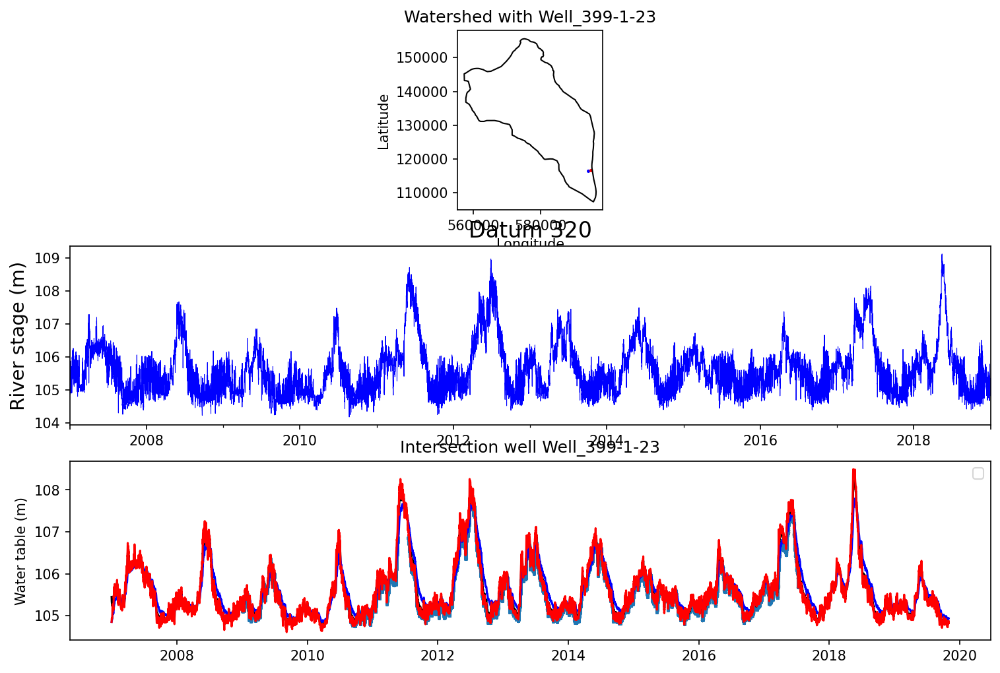

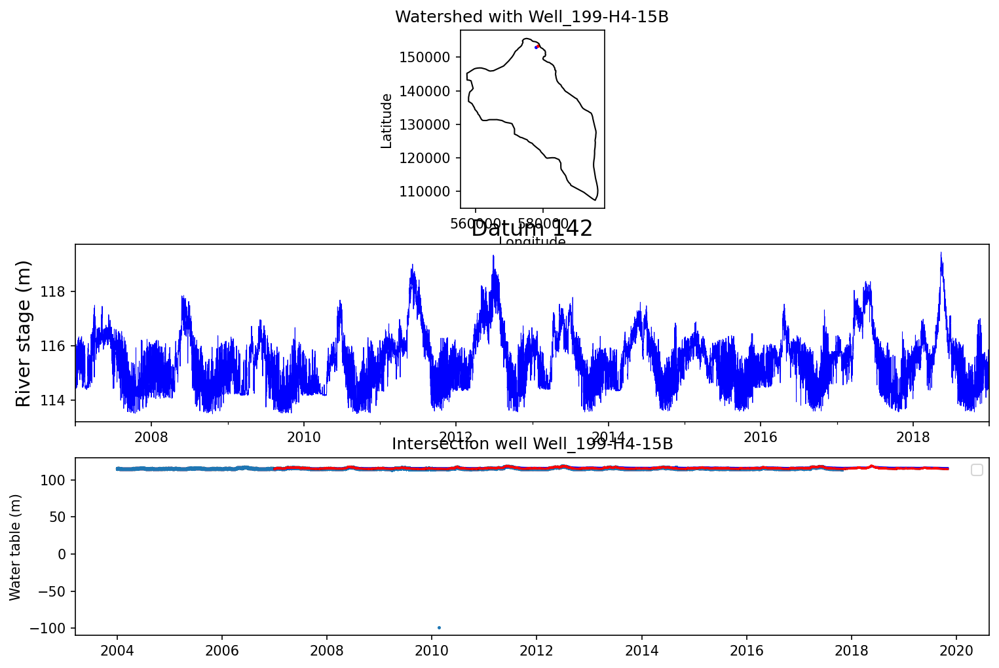

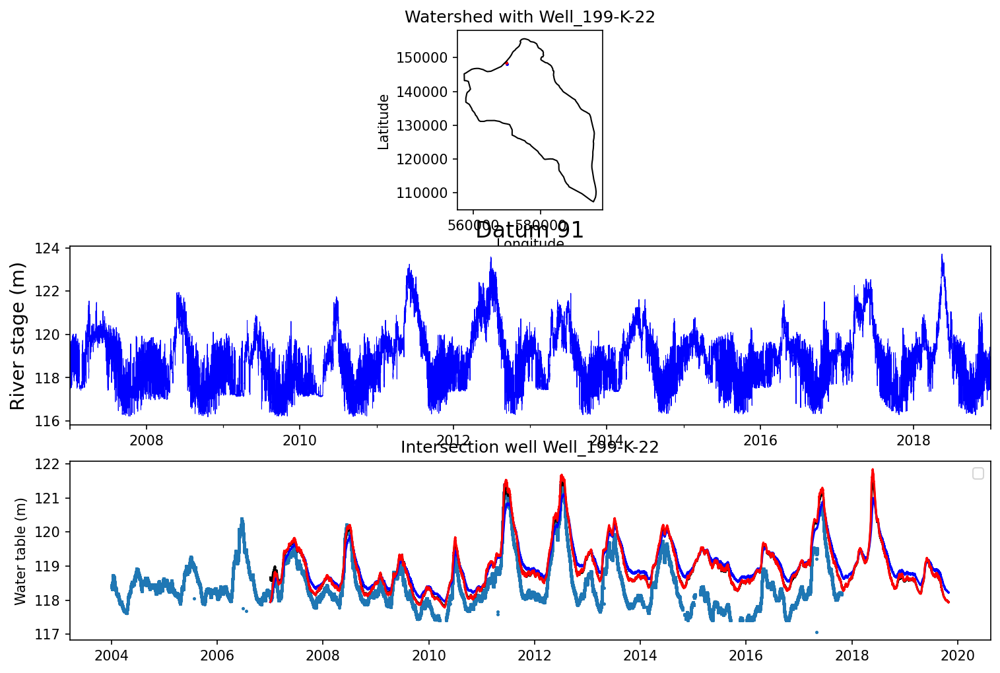

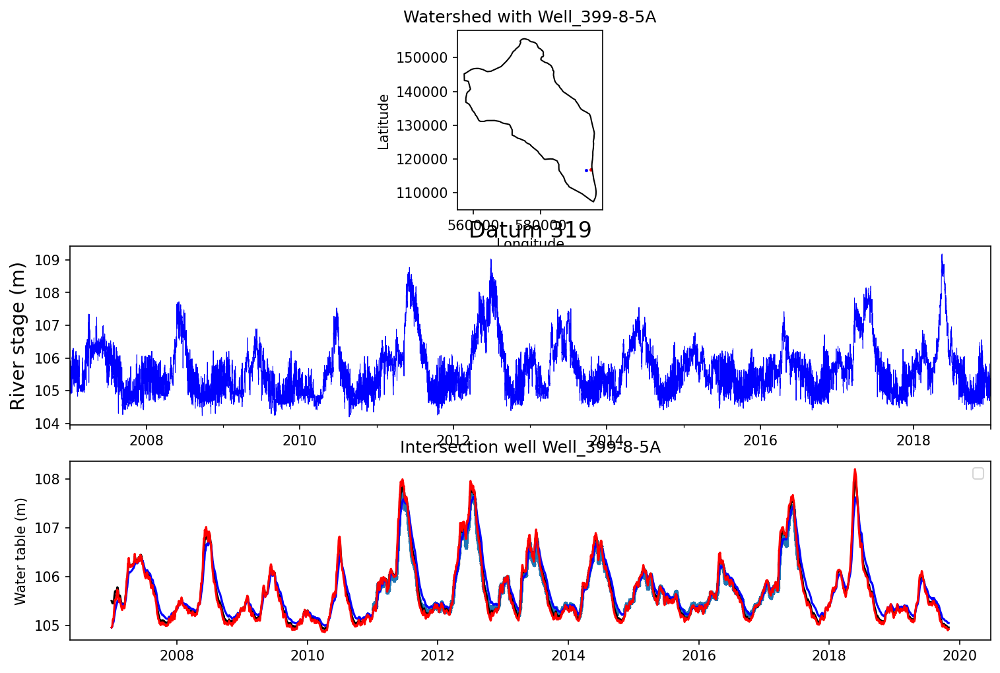

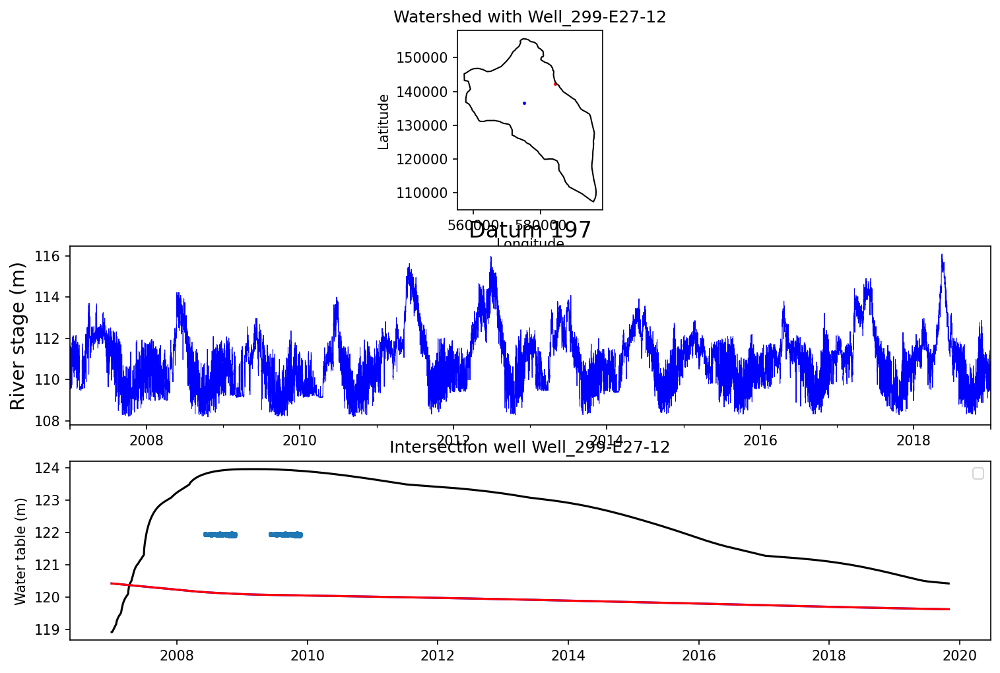

...

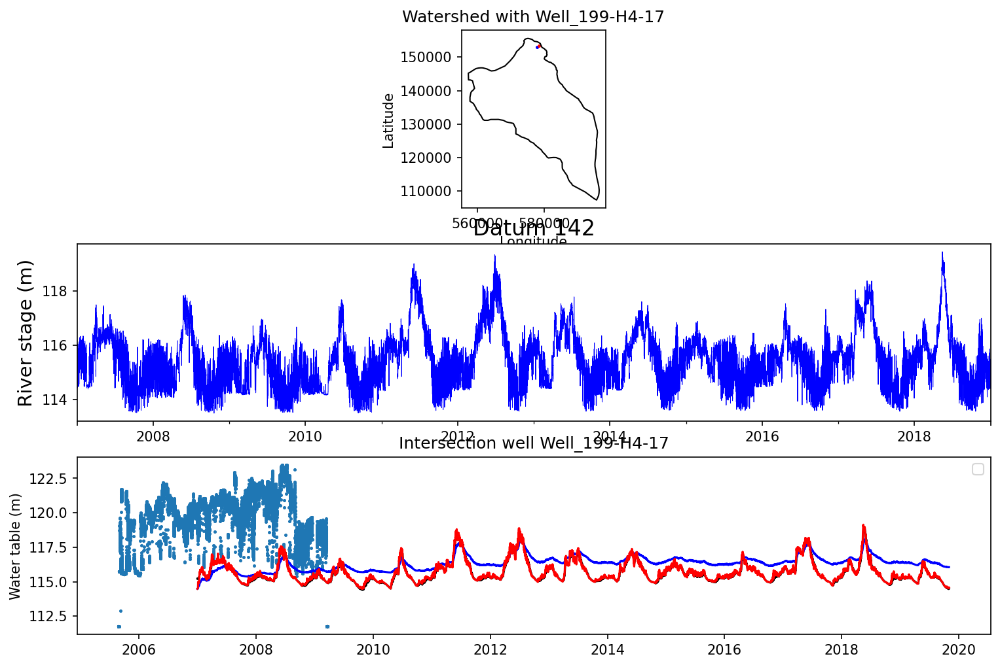

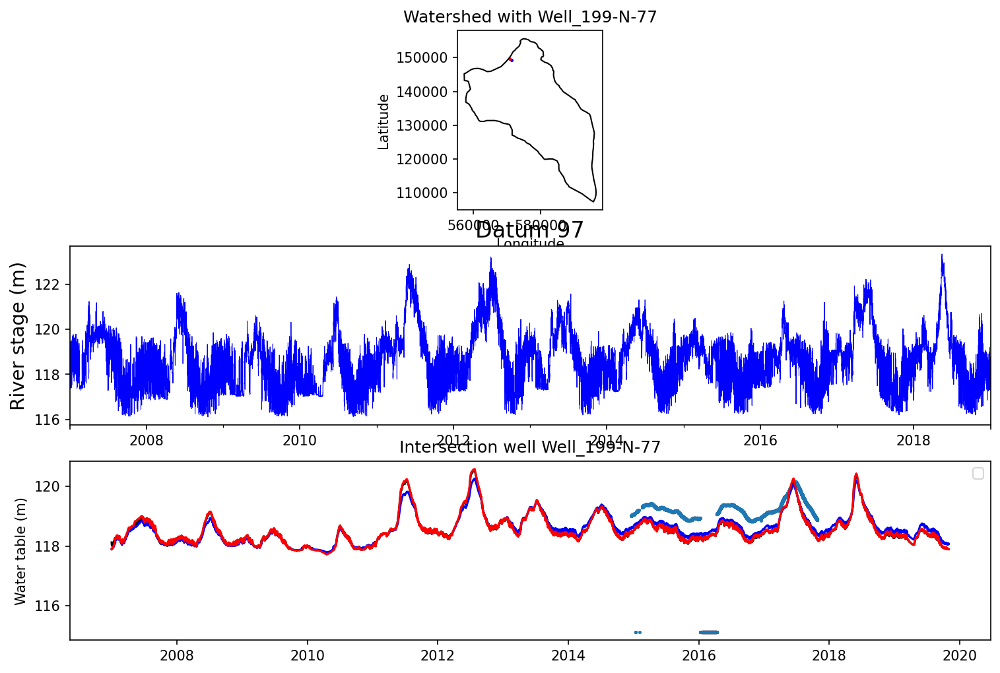

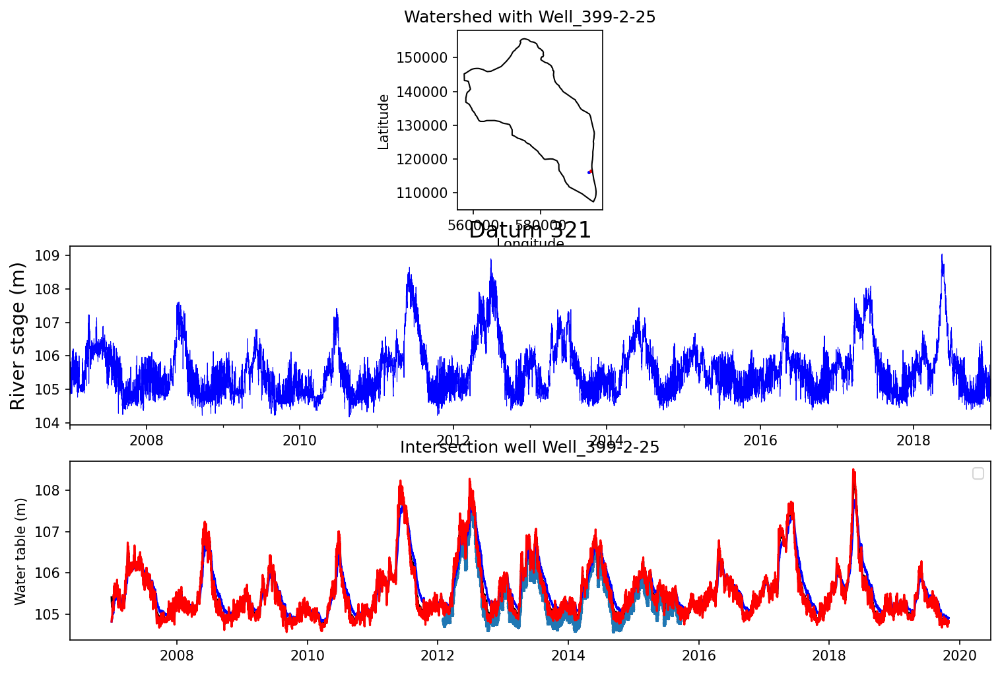

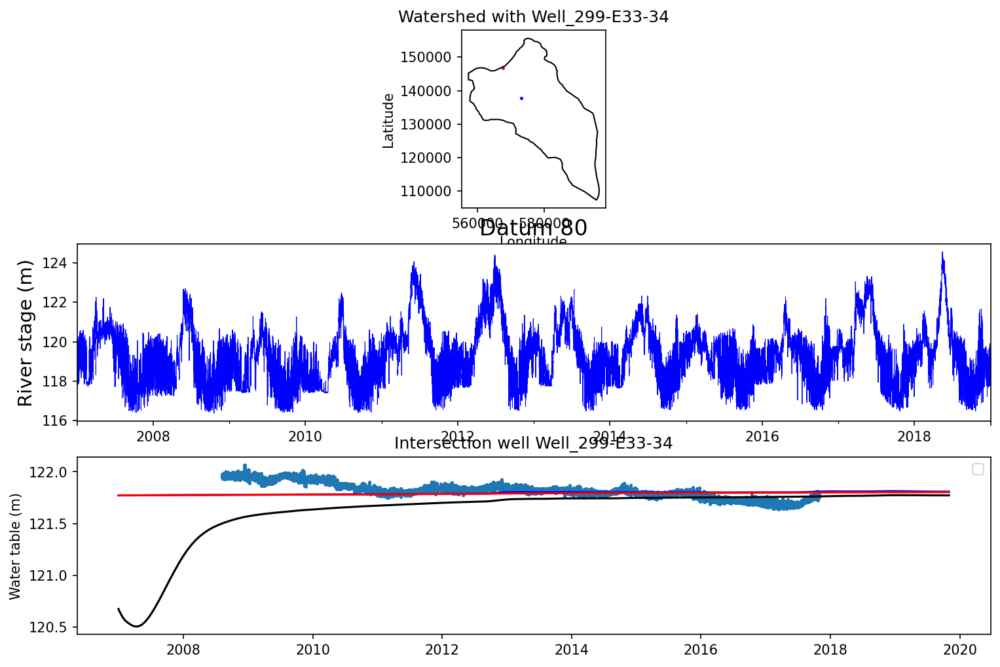

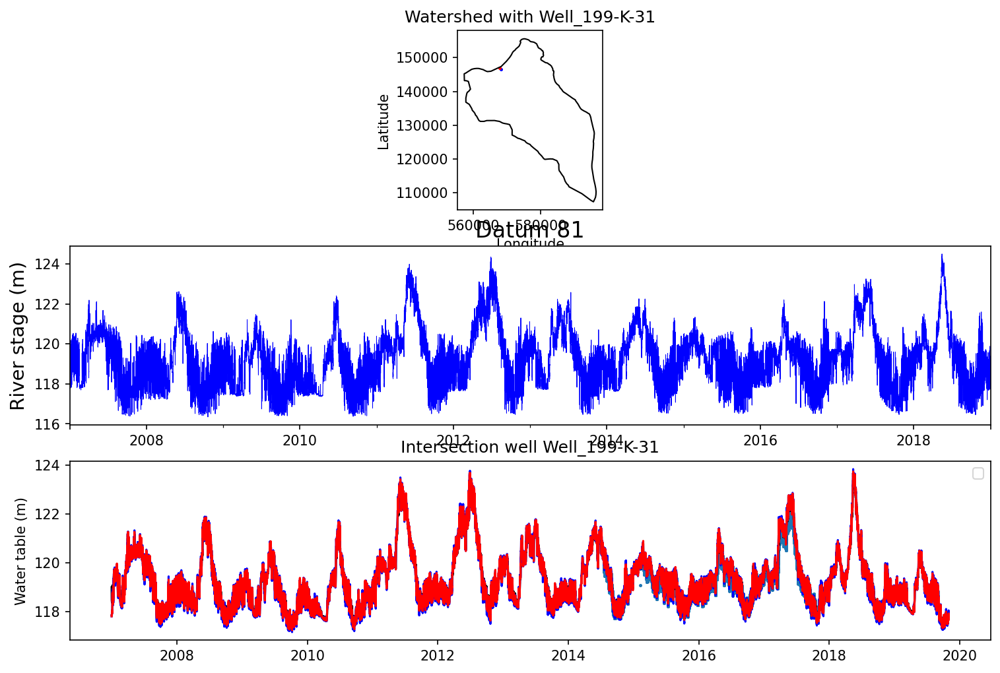

In [139]:
fdir_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'

metric_array = []   # initialize a empty array to store metric values

for index, iwell in enumerate(intersection_wells):
#    print(index)
#    print(iwell)
#---------plot the location of well and datum point in watershed geometry--------------------- 
    geometry = [Point(xy_iwell_list[index])]
    iwell_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

    geometry = [Point(xy_datum_list[index])]
    datum_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

    #plot
    fig, ax = plt.subplots(3,1,figsize=(12,8))
    watershed_bound.boundary.plot(ax=ax[0], color='black', linewidth=1, label='Watershed Boundary')

    iwell_coord_gdf.plot(ax=ax[0], color='blue', markersize=2, label='intersected well')
    datum_coord_gdf.plot(ax=ax[0], color='red', markersize=2, label='nearest datum point')

    ax[0].set_title(f'Watershed with Well_{iwell}')
    ax[0].set_xlabel('Longitude')
    ax[0].set_ylabel('Latitude')
    #ax.set_xlim(550000, 620000)
    #ax[0].legend()
    
#----------plot river stage at select datum point-------------------------------------------    
    datum_id = datum_index[index]
    fname_river_stage = 'DatumH_River_' + str(datum_id) + '.txt'
    f_river_stage = fdir_river_stage + fname_river_stage
    river_stage = pd.read_csv(f_river_stage, header = None, sep = " ", names = ['dt', 'Easting', 'Northing', 'wl'])
    river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
    river_stage.set_index('datetime', drop=False, inplace=True)    
    river_stage.plot(y='wl', color = 'blue', ax=ax[1], lw=0.5, zorder=1)

#     ax.scatter(river_stage.loc[itime, 'datetime'], river_stage.loc[itime, 'wl'], 
#                     facecolors = 'red', edgecolors= 'black', s = 30, alpha = 1,zorder=2)

    ax[1].set_ylabel('River stage (m)', fontsize = 14)
    ax[1].set_xlabel('')
    ax[1].set_title(f'Datum {datum_id}', fontsize=16)
    ax[1].get_legend().remove()
    ax[1].set_xlim(['01/01/2007','01/01/2019'])  

#-----------input three PF models data-------------------------
    iobs_head, iso_isimu_head, aniso_except_basalt_isimu_head, aniso_only_alluvium_isimu_head = model_comparison(
        iwell, iso_perm_well_data_df, aniso_perm_except_basalt_well_data_df, aniso_perm_only_alluvium_well_data_df, well_valid
    )
    
    ######## get metrics  ############
    # get the intersected time
    union_index = iso_isimu_head.index.intersection(iobs_head.index)
    
    #check if union_index is empty
    if union_index.empty:
        print(f'The union index is empty, skipping metric calculations for {iwell}')
        metric1, metric2, metric3 = None, None, None
    else:
        # rename the first column of dataframe to 'WL'
        iso_isimu_head.columns.values[0] = 'WL'
        metric1, _ = utils.get_metrics(union_index, iobs_head.loc[union_index,'WL'].values, union_index, iso_isimu_head.loc[union_index, 'WL'].values, metrics=['RMSE'])
        # rename the first column of dataframe to 'WL'
        aniso_except_basalt_isimu_head.columns.values[0] = 'WL'
        metric2, _ = utils.get_metrics(union_index, iobs_head.loc[union_index,'WL'].values, union_index, aniso_except_basalt_isimu_head.loc[union_index, 'WL'].values, metrics=['RMSE'])
        # rename the frist column of dataframe to 'WL'
        aniso_only_alluvium_isimu_head.columns.values[0] = 'WL'
        metric3, _ = utils.get_metrics(union_index, iobs_head.loc[union_index,'WL'].values, union_index, aniso_only_alluvium_isimu_head.loc[union_index, 'WL'].values, metrics=['RMSE'])

    # store the metric values
    metric_array.append((metric1,metric2,metric3)) 
    
    print('well index:{0}, well name:{1}'.format(index, iwell))
    print('isotropic perm model: {0}, anisotropic perm model(except basalt): {1}, anisotropic perm model (only alluvium): {2}'.format(metric1, metric2, metric3))

    ax[2].scatter(iobs_head.index,iobs_head.loc[:, 'WL'], s=2)
    ax[2].plot(iso_isimu_head.index, iso_isimu_head.iloc[:, -1],'k-')
    ax[2].plot(aniso_except_basalt_isimu_head.index, aniso_except_basalt_isimu_head.iloc[:, -1],'b-')
    ax[2].plot(aniso_only_alluvium_isimu_head.index, aniso_only_alluvium_isimu_head.iloc[:, -1],'r-')

    ax[2].legend(['obs_head','simu_head(iso perm)', 'simu_head(aniso-except basalt)', 'simu_head(aniso-only alluvidum)'])
    ax[2].set_title(f"Intersection well Well_{iwell}")
    ax[2].set_ylabel('Water table (m)')
    #ax[2].set_ylim([114,120])
    ax[2].legend()
    
    #start_window = '2013-01-01 00:00:00'
    #end_window = '2015-01-01 00:00:00'
    #ax.set_xlim(start_window, end_window)
    #ax.set_ylim(104.5,108.5)
    
    #plt.tight_layout()
    #plt.show()
    
    # save figure to seperate folder
    #fname_simu_obs_head = '/pscratch/sd/z/zc727/OUTPUT/WL/'
    #fig.savefig(fname_simu_obs_head + 'simu_obs_'+iwell + '.png', dpi=150)
    #plt.close(fig)

In [140]:
#print(metric_array)
#print(iso_isimu_head[union_index,'WL'])

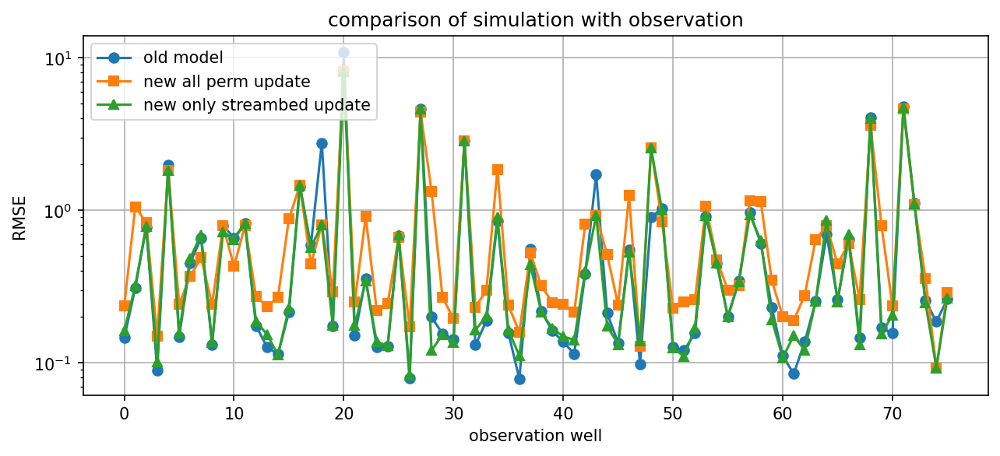

In [161]:
# extract the metric value array

# Extracting only the RMSE values
value_array = []

for row in metric_array:
    if row is not None and any(item is not None for item in row):
        # Extract RMSE values for each row
        values = [item['RMSE'] for item in row if item is not None]
        value_array.append(values)

# Convert to a NumPy array
value_array = np.array(value_array)

# Plotting
plt.figure(figsize=(10, 4))  # Create a figure with a custom size

# Plot each column as a separate dotted curve
plt.plot(value_array[:, 0], linestyle='-', marker='o', label='old model')
plt.plot(value_array[:, 1], linestyle='-', marker='s', label='new all perm update')
plt.plot(value_array[:, 2], linestyle='-', marker='^', label='new only streambed update')

# Adding labels and titles
plt.xlabel('observation well')
plt.yscale('log')
plt.ylabel('RMSE')
plt.title('comparison of simulation with observation')
plt.legend()  # Add legend to differentiate curves
plt.grid(True)  # Enable grid for better readability

# Show plot
plt.show()

# end of comparison

# plot simulation tracer vs observation speC

### import observation speC

In [146]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
fname_300A_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/300A_wells_2008-2019.csv'
obs_data_df = pd.read_csv(fname_300A_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

### import simulation data(isotropic perm)

In [142]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-isotro_perm/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df_ave.xz', "rb") as f:
    iso_perm_well_data_df_ave = pickle.load(f)

### import simulation data(anisotropic perm-except basalt)

In [143]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-aniso_perm_except_basalt/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df_ave.xz', "rb") as f:
    aniso_perm_except_basalt_well_data_df_ave = pickle.load(f)

### import simulation data(anisotropic perm-only alluvium)

In [144]:
pickle_dir = '/global/homes/z/zc727/HFR/output/'
case_name = "HFR-aniso_perm_only_alluvium/"
with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df_ave.xz', "rb") as f:
    aniso_perm_only_alluvium_well_data_df_ave = pickle.load(f)

In [19]:
print(iso_perm_well_data_df_ave.columns)

MultiIndex([(    'RG3_T3_24cm',   'Liquid Pressure [Pa]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm', 'Total Tracer_river [M]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qlx [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qly [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_64cm',   'Liquid Pressure [Pa]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm', 'Total Tracer_river [M]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qlx [m/h]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qly [m/h]',     'RG3_T3_64cm'),
            (  'T1_104.5_45cm',   'Liquid Pressure [Pa]',   'T1_104.5_45cm'),
            (  'T1_104.5_45cm', 'Total Tracer_river [M]',   'T1_104.5_45cm'),
            ...
            ('Well_699-43-41E', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            ('Well_699-43-41F', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            ('Well_699-43-41G', 'Total Tracer_ri

In [ ]:
#intersected well number: 36
#['Well_399-1-21B', 'Well_399-3-22', 'Well_399-1-12', 'Well_399-1-11', 'Well_399-4-11', 'Well_399-2-5', 'Well_399-3-34', 'Well_399-3-21', 'Well_399-3-18', 'Well_399-1-15', 'Well_399-3-19', 
# 'Well_399-1-1', 'Well_399-2-3', 'Well_399-1-17A', 'Well_399-1-2', 'Well_399-3-37', 'Well_399-4-7', 'Well_399-1-60', 'Well_399-2-33', 'Well_399-5-1', 'Well_399-3-20', 'Well_399-1-32', 
# 'Well_399-2-10', 'Well_399-4-9', 'Well_399-3-10', 'Well_399-1-23', 'Well_399-2-1', 'Well_399-2-32', 'Well_399-1-21A', 'Well_399-1-10A', 'Well_399-1-16A', 'Well_399-8-5A', 'Well_399-1-7', 'Well_399-2-2', 'Well_399-3-9', 'Well_399-2-25']

In [148]:
well_list_300A = well_300A_sub['WellName'].unique()
intersection_wells_300A = list(set(well_list_300A).intersection(sim_unique_well_list))
print('intersected well number in 300A: {0}'.format(len(intersection_wells_300A)))
print(intersection_wells_300A)

intersected well number in 300A: 35
['399-1-23', '399-2-33', '399-3-34', '399-8-5A', '399-2-1', '399-2-32', '399-1-21A', '399-5-1', '399-3-9', '399-3-18', '399-1-10A', '399-1-11', '399-1-60', '399-1-2', '399-2-10', '399-4-9', '399-1-7', '399-1-12', '399-1-1', '399-3-20', '399-3-22', '399-3-37', '399-1-21B', '399-2-3', '399-3-10', '399-4-7', '399-1-15', '399-2-5', '399-1-16A', '399-2-25', '399-2-2', '399-3-19', '399-3-21', '399-1-17A', '399-1-32']


In [149]:
xy_iwell_list_300A = []
for iwell in intersection_wells_300A:
    well_cds = well_coord.loc[iwell] if iwell in well_coord.index else None
    if well_cds is None:
        print(f"Warning: well '{iwell}' is not found in well_coord.")
        continue
        
    xy_iwell_list_300A.append(well_cds.to_numpy())
    
xy_iwell_300A = np.array(xy_iwell_list_300A)

In [150]:
# remove the well '399-1-1' from the intersected well
intersection_wells_300A.remove('399-1-1')

In [153]:
print(iso_perm_well_data_df_ave.columns)

MultiIndex([(    'RG3_T3_24cm',   'Liquid Pressure [Pa]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm', 'Total Tracer_river [M]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qlx [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qly [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_64cm',   'Liquid Pressure [Pa]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm', 'Total Tracer_river [M]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qlx [m/h]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qly [m/h]',     'RG3_T3_64cm'),
            (  'T1_104.5_45cm',   'Liquid Pressure [Pa]',   'T1_104.5_45cm'),
            (  'T1_104.5_45cm', 'Total Tracer_river [M]',   'T1_104.5_45cm'),
            ...
            ('Well_699-43-41E', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            ('Well_699-43-41F', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            ('Well_699-43-41G', 'Total Tracer_ri

In [160]:
for index, iwell in enumerate(intersection_wells_300A):
#    print(index)
#    print(iwell)
#---------plot the location of well and datum point in watershed geometry--------------------- 
    geometry = [Point(xy_iwell_list_300A[index])]
    iwell_coord_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

    #plot
    fig, ax = plt.subplots(2,1,figsize=(12,8))
    watershed_bound.boundary.plot(ax=ax[0], color='black', linewidth=1, label='Watershed Boundary')

    iwell_coord_gdf.plot(ax=ax[0], color='blue', markersize=2, label='selected well')

    ax[0].set_title(f'Watershed with Well_{iwell}')
    ax[0].set_xlabel('Longitude')
    ax[0].set_ylabel('Latitude')

    iwell_name = 'Well_'+iwell
    iso_isimu_df = iso_perm_well_data_df_ave[iwell_name,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()
    aniso_except_basalt_isimu_df = aniso_perm_except_basalt_well_data_df_ave[iwell_name,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()
    aniso_only_alluvium_isimu_df = aniso_perm_only_alluvium_well_data_df_ave[iwell_name,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()
#isimu_head = (isimu_head - P_atm) / rho / g_const
#isimu_head.dropna(axis = 1, inplace = True)

#for i in isimu_df.columns:
#  isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    iso_simu_time = np.array([date_origin + timedelta(hours=i) for i in iso_isimu_df.index])
    aniso_except_basalt_simu_time = np.array([date_origin + timedelta(hours=i) for i in aniso_except_basalt_isimu_df.index])
    aniso_only_alluvium_simu_time = np.array([date_origin + timedelta(hours=i) for i in aniso_only_alluvium_isimu_df.index])

#isimu_df['DateTime'] = simu_time
#isimu_df.set_index('DateTime', inplace=True)
#isimu_df.set_index(simu_time)

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)
   
    ax[1].plot(iso_simu_time, iso_isimu_df.values, 'k-')
    ax[1].plot(aniso_except_basalt_simu_time, aniso_except_basalt_isimu_df.values,'b-')
    ax[1].plot(aniso_only_alluvium_simu_time, aniso_only_alluvium_isimu_df.values,'r-')
    
    ax11 = ax[1].twinx()
    ax11.plot(iobs_df.index,iobs_df.loc[:, 'SpC'], 'c-')
    ax11.set_ylabel('SpC (ms/cm)')
    ax11.legend(['SpC'],loc=[0.31, 1.01], frameon = False)
    
    start_window = '01/01/2017'
    end_window = '01/01/2019'
    
# Convert window strings to datetime objects
    start_window_dt = datetime.strptime(start_window, '%m/%d/%Y')
    end_window_dt = datetime.strptime(end_window, '%m/%d/%Y')
    
    #ax[2].set_xlim(start_window_dt, end_window_dt)
    ax[1].set_ylim([0, 1])
    ax[1].legend(loc=[0.01, 1.01], frameon = False)
    ax[1].set_title(iwell, fontsize = 16, pad = 30)
    ax[1].set_ylabel('River tracer (-)', color = 'r')
    ax[1].tick_params('y', colors='r')
    
    print(f'well:{iwell} is output')
    
    #plt.tight_layout()
    #plt.show()
    
    # save figure to seperate folder
    fname_simu_obs_tracer = '/pscratch/sd/z/zc727/OUTPUT/Model_Comparison/Tracer/'
    fig.savefig(fname_simu_obs_tracer + 'comp_tracer_'+iwell + '.png', dpi=150)
    plt.close(fig)

2024-12-17 10:01:38,067 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-23 is output


2024-12-17 10:01:38,753 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-33 is output


2024-12-17 10:01:39,439 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-34 is output


2024-12-17 10:01:40,188 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-8-5A is output


2024-12-17 10:01:40,851 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-1 is output


2024-12-17 10:01:41,564 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-32 is output


2024-12-17 10:01:42,244 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-21A is output


2024-12-17 10:01:42,923 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-5-1 is output


2024-12-17 10:01:43,575 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-9 is output


2024-12-17 10:01:44,256 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-18 is output


2024-12-17 10:01:44,956 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-10A is output


2024-12-17 10:01:45,698 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-11 is output


2024-12-17 10:01:46,393 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-60 is output


2024-12-17 10:01:47,066 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-2 is output


2024-12-17 10:01:47,757 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-10 is output


2024-12-17 10:01:48,444 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-4-9 is output


2024-12-17 10:01:49,151 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-7 is output


2024-12-17 10:01:49,848 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-12 is output


2024-12-17 10:01:50,544 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-20 is output


2024-12-17 10:01:51,290 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-22 is output


2024-12-17 10:01:51,938 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-37 is output


2024-12-17 10:01:52,602 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-21B is output


2024-12-17 10:01:53,240 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-3 is output


2024-12-17 10:01:53,925 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-10 is output


2024-12-17 10:01:54,613 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-4-7 is output


2024-12-17 10:01:55,295 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-15 is output


2024-12-17 10:01:55,964 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-5 is output


2024-12-17 10:01:56,724 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-16A is output


2024-12-17 10:01:57,418 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-25 is output


2024-12-17 10:01:58,069 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-2-2 is output


2024-12-17 10:01:58,775 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-19 is output


2024-12-17 10:01:59,458 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-3-21 is output


2024-12-17 10:02:00,126 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-17A is output


2024-12-17 10:02:00,799 - matplotlib.legend - WARNING: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


well:399-1-32 is output
